# Wall reconstruction from parallel links

For every parallel link in the room sweeps, a model predicts its distance from the closest parallel wall. The
prediction comes from the link's own θ̂ and α̂ only, with no direction, length or location input. The model never
says which side the wall is on, so each link gives a probability for the wall's position that is split evenly
between the two sides of the link. This notebook turns the held-out predictions into those probabilities, shows
them per link, and sums them over all links into a map of where the walls are likely to be.

**Predictions.** They are made exactly as in `python roomsweeps_wall_distance.py --length-cm 92 --loo
--max-wall-cm CAP`, for CAP = 100, 200 and 300 cm. That is leave one experiment out, with the other experiments'
copies of the held-out label pairs dropped from training. Every prediction used below is therefore for a link the
model never saw.

**Probability for one link.** Take a link with midpoint coordinate $c$ on the axis perpendicular to it and
predicted distance $\hat d$. The wall position $s$ on that axis has the density

$$p(s) = \tfrac12\,\mathcal N(s;\, c + \hat d,\, \sigma) + \tfrac12\,\mathcal N(s;\, c - \hat d,\, \sigma).$$

Here σ is the RMSE of the model's held-out predictions at that cutoff, so the spread matches how wrong the model
actually is. The axis for direction 0 links is the distance from the Row-1 wall. The axis for direction 1 links is
the distance from the Edge02 wall. Both are measured in the merged room scan.

In [1]:
import contextlib
from pathlib import Path
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d
from IPython.display import Image, display

import sys
sys.path.insert(0, "../gridsim_processing")   # gridsim_wall_distance (cwd = organized_multitag/roomsweeps_processing)

from roomsweeps_wall_distance import (DATA_DIR, FREQ_RANGE, MESH_PATH, N_COLS, N_ROWS, ROOT, TILE_CM, WALL_Z,
                                      all_positions, build_dataset, evaluate, find_walls, grid_xy, label_grid,
                                      load_bidir, parallel_links, plot_errors, wall_distance_cm)
from roomsweeps_wall_distance import models as sk_models
from gridsim_wall_distance import TransformerRegressor
from roomsweeps_wall_distance_posttrain import ResCNNRegressor

LENGTHS_CM = (46,92,138,184)             # link lengths, as --length-cm 92
CAPS_CM = (100, 200, 300)      # --max-wall-cm of each run
FAR_CM = 200                   # uncapped run: a link is "far" when its wall is more than this away
# Iterative wall localization (last section)
ITER_CAPS_CM = (200, 150, 100, 50)   # Model_X for each X; the iteration narrows through them. The classifier asks
                                     # whether the wall is more than ITER_CAPS_CM[0] away
CLASSIFIER = "SVC"                   # "SVC" or "MLP"
ITER_CUTOFF = 0.65                   # a side's wall is accepted only where its support reaches this
ITER_FALLBACK = False                # after the initial step, retry the sides without a wall with all links, Model_∞
ITER_SIGMA_MIN_CM = 10               # floor on σ (Model_50 is trained on links at nearly one distance)
INNER_FOLDS = 5                      # folds over the training experiments that estimate σ without test truth
ITER_TOL_CM = 30                     # scoring only: a candidate within this of its link's wall counts as correct
MODEL = "SVR"                  # model whose predictions become the wall probabilities (any name in `summary`)
SEED = 0
OUT = Path.cwd() / "reconstruction_out"
OUT.mkdir(exist_ok=True)
n_tiles = sorted({int(round(L / TILE_CM)) for L in LENGTHS_CM})

# Models fitted in every leave-one-experiment-out fold. "mean of train" is always fitted too: it is the baseline of
# every plot and table. MODEL must be one of these.
# MODELS = ["SVR", "MLP", "Transformer (scratch)", "ResCNN (scratch)"]
MODELS = ["SVR"]
assert MODEL in MODELS, f"MODEL = {MODEL!r} is not in MODELS"

# The networks are trained from scratch on each fold's real training links, with the settings of
# roomsweeps_wall_distance_posttrain.py (--scratch): transformer 200 epochs at lr 1e-3, dim 64, 3 layers;
# ResCNN 60 epochs at lr 1e-3, width 64. Both use batch 32 and weight decay 1e-2.
TF_SCRATCH = dict(epochs=200, batch_size=32, lr=1e-3, weight_decay=1e-2, dim=64, layers=3)
CNN_SCRATCH = dict(epochs=60, batch_size=32, lr=1e-3, weight_decay=1e-2)

def token_cols():
    # columns of X that form the frequency tokens: θ̂ in 0…F-1, α̂ in F…2F-1
    F = len(FREQS)
    return np.arange(F)[None] + F * np.arange(2)[:, None]

BUILDERS = {   # name -> (X_train, y_train, seed) -> fitted model with .predict
    **{name: (lambda X, y, seed, name=name: sk_models(seed)[name].fit(X, y)) for name in sk_models(0)},
    "Transformer (scratch)": lambda X, y, seed: TransformerRegressor(token_cols(), seed=seed, log_every=0,
                                                                     **TF_SCRATCH).fit(X, y),
    "ResCNN (scratch)": lambda X, y, seed: ResCNNRegressor(FREQS, attn=True).fit(X, y, seed=seed, **CNN_SCRATCH),
}
unknown = set(MODELS) - set(BUILDERS)
assert not unknown, f"unknown models {sorted(unknown)}; choose from {list(BUILDERS)}"

def fit_fn(X, y, tr, te, seed):
    # fit_fn for evaluate: mean of train plus every model in MODELS
    assert X.shape[1] == 2 * len(FREQS)
    preds, train_mae = {"mean of train": np.full(len(te), y[tr].mean())}, {}
    for name in MODELS:
        model = BUILDERS[name](X[tr], y[tr], seed)
        preds[name] = model.predict(X[te])
        train_mae[name] = np.abs(model.predict(X[tr]) - y[tr]).mean()
    return preds, train_mae

## Data: tag positions, scanned walls, $\hat{\theta}$ and $\hat{\alpha}$

In [2]:
positions = all_positions()
exps = [e for e in positions if any((DATA_DIR / e).glob("*.csv"))]
walls = find_walls()
bidir = {e: load_bidir(e) for e in exps}
FREQS = np.array(sorted(f for f in bidir[exps[0]]["freq"].unique() if FREQ_RANGE[0] <= f <= FREQ_RANGE[1]))  # X's columns

REF = {0: "Row-1 wall (beyond row 1)", 1: "Edge02 wall (beyond col 0)"}   # axis origin for each link direction
AXIS_NAME = {0: "distance from the Row-1 wall (cm)", 1: "distance from the Edge02 wall (cm)"}
wall_pos = {d: {name: wall_distance_cm(w[0], walls[REF[d]]) for name, w in walls.items() if w[2] == d} for d in (0, 1)}

print(f"{len(exps)} experiments: {', '.join(exps)}")
for d in (0, 1):
    print(f"direction {d} links, axis = {AXIS_NAME[d]}:")
    for name, s in wall_pos[d].items():
        print(f"  {name:<30} at {s:6.1f} cm")

17 experiments: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17
direction 0 links, axis = distance from the Row-1 wall (cm):
  Row-1 wall (beyond row 1)      at    0.0 cm
  Row-8 wall (beyond row 8)      at  646.4 cm
direction 1 links, axis = distance from the Edge02 wall (cm):
  Edge02 wall (beyond col 0)     at    0.0 cm
  Edge01 wall (beyond col 16)    at  847.3 cm


## Held-out predictions at each cutoff

`evaluate` is the leave-one-experiment-out loop of `roomsweeps_wall_distance.py`, called with dedup on as in the
command line. Its per-fold printout is kept in `runs[cap]["log"]`.

In [3]:
def metrics_row(y, p):
    e = p - y
    return {"MAE (cm)": np.abs(e).mean(), "RMSE (cm)": np.sqrt((e ** 2).mean()),
            "≤ 15 cm (%)": 100 * (np.abs(e) <= 15).mean()}

runs, rows = {}, []
for cap in CAPS_CM:
    links = parallel_links(positions, exps, n_tiles, walls, max_wall_cm=cap)
    X, y, meta, freqs = build_dataset(links, bidir, FREQ_RANGE)
    log = io.StringIO()
    with contextlib.redirect_stdout(log):
        te, preds = evaluate(X, y, meta, 0.7, SEED, loo=True, loo_dedup=True, keep_mean=True,
                            fit_fn=fit_fn)
    runs[cap] = {"meta": meta.iloc[te].reset_index(drop=True), "y": y[te], "preds": preds, "log": log.getvalue()}
    for name, p in preds.items():
        rows.append({"cap (cm)": cap, "links": len(te), "model": name, **metrics_row(y[te], p[te] if len(p) > len(te) else p)})
summary = pd.DataFrame(rows).set_index(["cap (cm)", "links", "model"])
summary.round(1)

MAE (cm)  RMSE (cm)  ≤ 15 cm (%)
cap (cm) links model                                          
100      130   mean of train      16.9       19.1         30.8
               SVR                15.0       19.0         60.0
200      399   mean of train      42.5       49.9         25.6
               SVR                43.3       52.9         20.8
300      609   mean of train      65.1       77.3         15.4
               SVR                72.3       87.6         11.7

### Error distribution of each run

These figures come from `plot_errors` in `roomsweeps_wall_distance.py`. If the model's curves sit on the dashed
mean-of-train line, the model has learned nothing beyond the average distance.

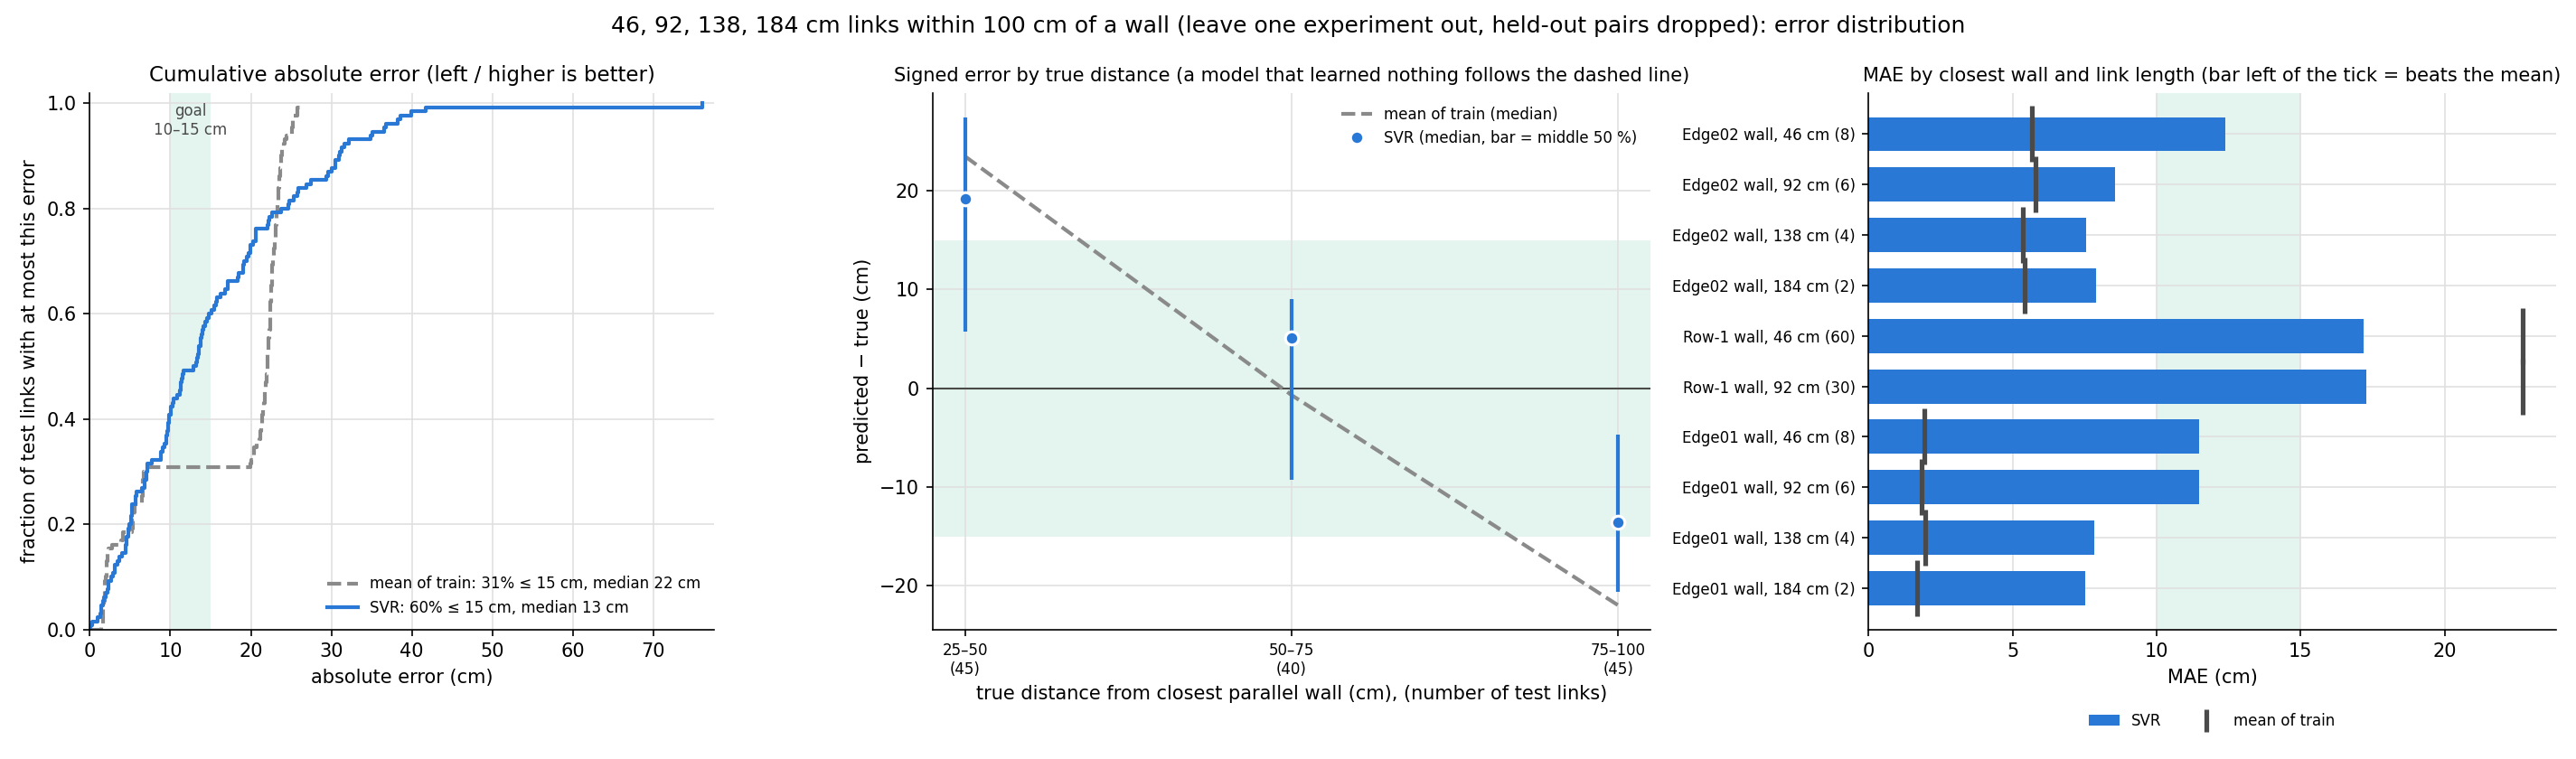

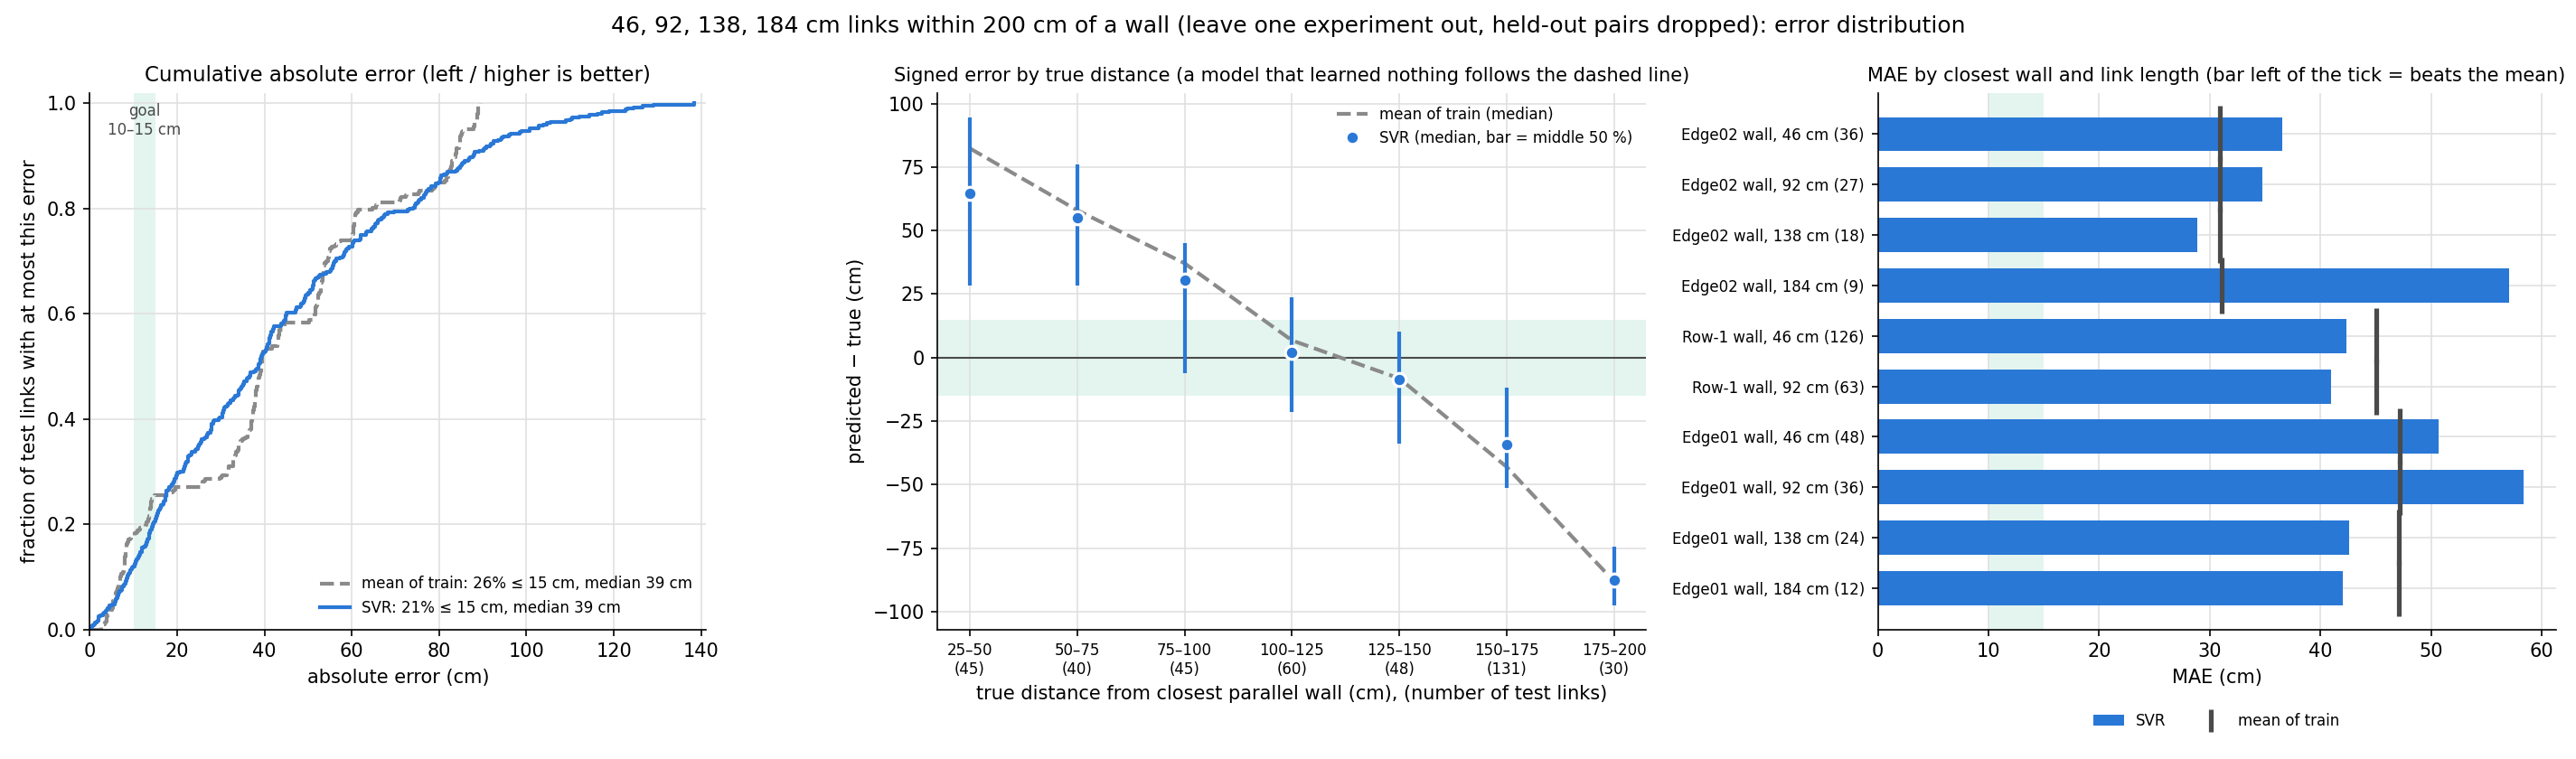

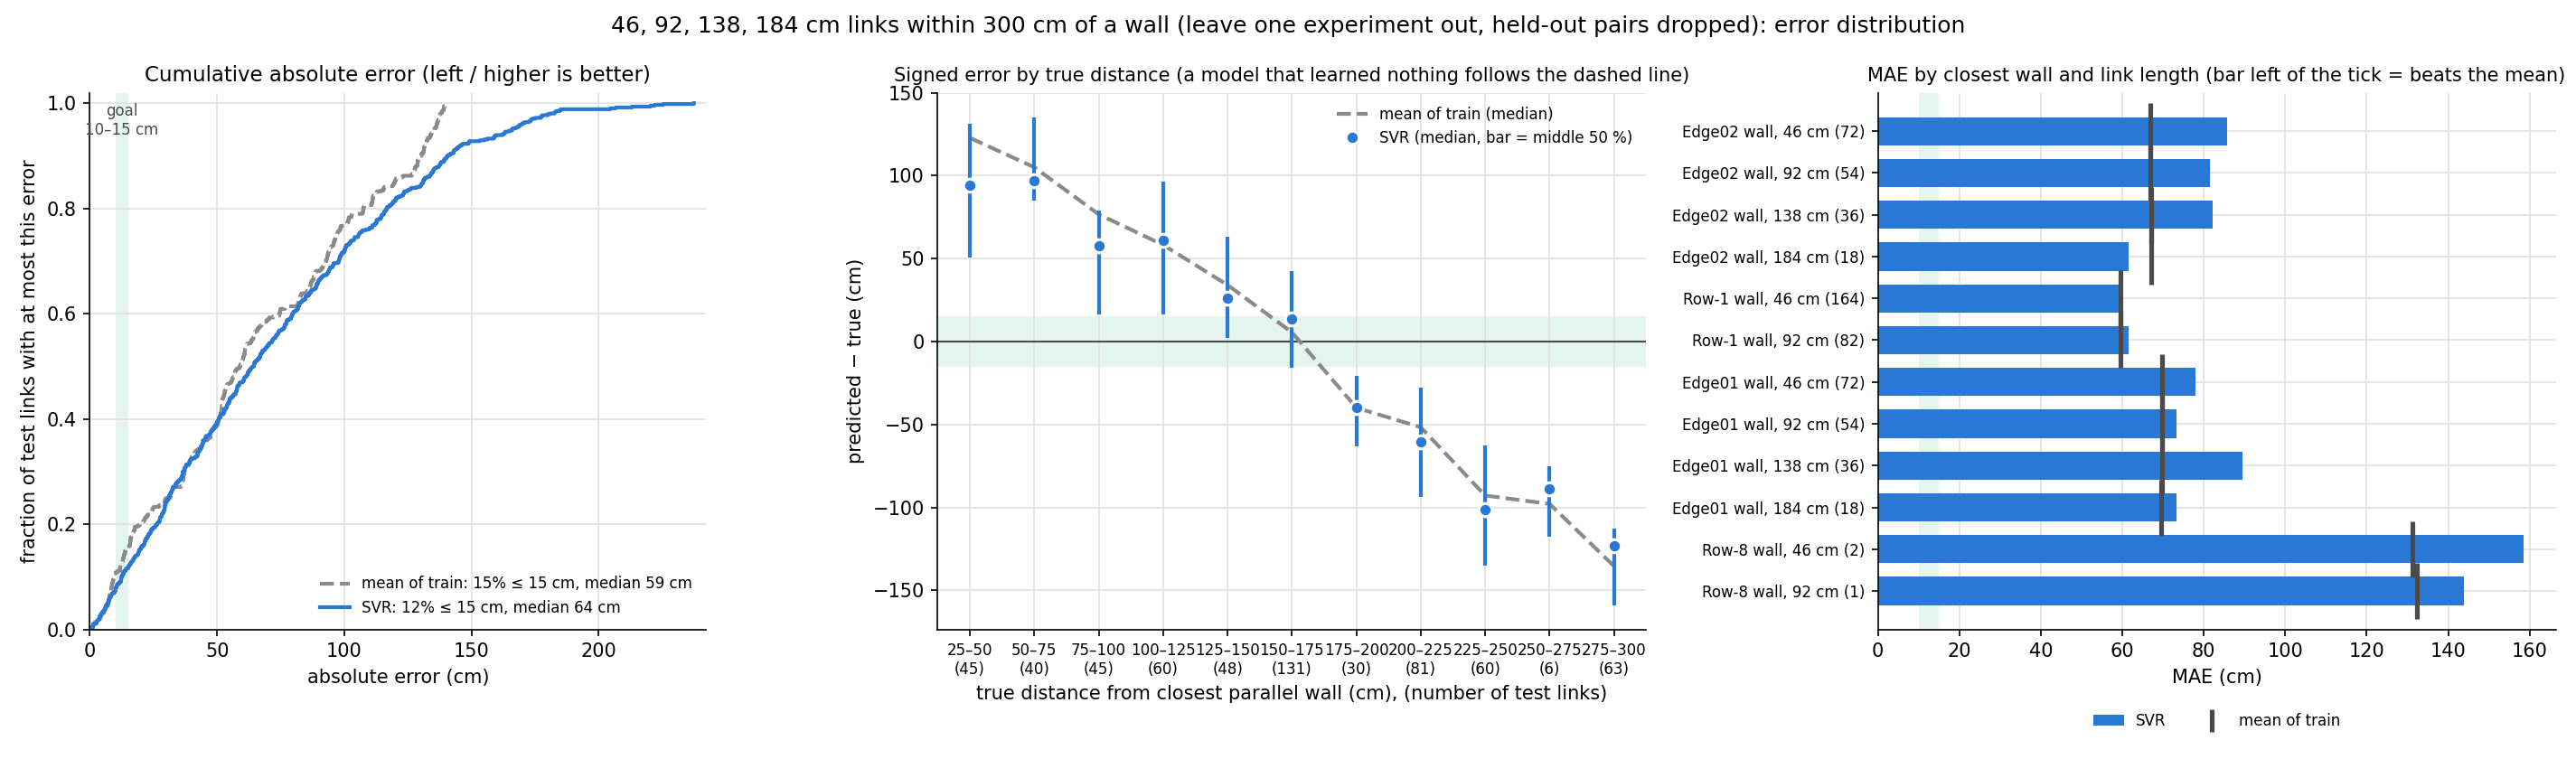

In [4]:
for cap, r in runs.items():
    preds = {k: v for k, v in r["preds"].items() if k != "mean of train"}
    path = OUT / f"errors_loo-dedup_max{cap}cm.png"
    with contextlib.redirect_stdout(io.StringIO()):
        plot_errors(r["y"], preds, r["preds"]["mean of train"], r["meta"], path,
                    f"{', '.join(map(str, LENGTHS_CM))} cm links within {cap} cm of a wall "
                    "(leave one experiment out, held-out pairs dropped): error distribution")
    display(Image(str(path)))

## Wall probability for each link

Each row below is one held-out link prediction, sorted by the link's midpoint on the axis. The colour is that
link's wall probability, scaled to its own maximum. An orange tick marks the link midpoint. The dashed lines are the
true walls from the room scan, and the grey band is the floor area the tags cover, where no wall can be. The top
strip is the average over all links.

A useful model puts both bright blobs of a row on a dashed line. When the prediction is right, one blob lands on
the real wall and the other on its mirror image across the link.

In [5]:
def link_axis(meta):
    # midpoint coordinate c (cm) of every link on its direction's axis
    c = np.empty(len(meta))
    for i, (la, lb, d) in enumerate(zip(meta["label_a"], meta["label_b"], meta["direction"])):
        mid = (grid_xy(*label_grid(la)) + grid_xy(*label_grid(lb))) / 2
        c[i] = wall_distance_cm(mid, walls[REF[d]])
    return c

def link_density(s, c, dhat, sigma):
    # (links, len(s)) wall density, half on each side of every link
    g = lambda mu: np.exp(-0.5 * ((s[None] - mu[:, None]) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi))
    return 0.5 * g(c + dhat) + 0.5 * g(c - dhat)

def tag_extent(d):
    # range of the tag grid on direction d's axis (all tag labels in any experiment)
    labels = {l for pos in positions.values() for l in pos["label"]}
    s = [wall_distance_cm(grid_xy(*label_grid(l)), walls[REF[d]]) for l in labels]
    return min(s), max(s)

for cap, r in runs.items():
    r["c"] = link_axis(r["meta"])
    r["sigma"] = {name: np.sqrt(((p - r["y"]) ** 2).mean()) for name, p in r["preds"].items()}
    print(f"cap {cap} cm: σ = " + ", ".join(f"{k} {v:.1f} cm" for k, v in r["sigma"].items()))

# walls that some link is closest to (the Row-8 wall only gets links from exps 16-17, rows 4-8, at caps ≥ 300 cm)
seen = set().union(*(set(r["meta"]["wall"]) for r in runs.values()))
used_pos = {d: {name: s for name, s in wall_pos[d].items() if name in seen} for d in (0, 1)}
print("walls with links:", ", ".join(n for d in (0, 1) for n in used_pos[d]))

def axis_grid(d, margin=150):
    # axis positions (cm) covering the tag grid and the walls with links, plus a margin
    ends = [*tag_extent(d), *used_pos[d].values()]
    return np.arange(min(ends) - margin, max(ends) + margin, 2.0)

S = {d: axis_grid(d) for d in (0, 1)}                   # for the per-link plots and the reconstruction table
S_MAP = {d: axis_grid(d, margin=1200) for d in (0, 1)}  # wide enough for the whole room map

cap 100 cm: σ = mean of train 19.1 cm, SVR 19.0 cm
cap 200 cm: σ = mean of train 49.9 cm, SVR 52.9 cm
cap 300 cm: σ = mean of train 77.3 cm, SVR 87.6 cm
walls with links: Row-1 wall (beyond row 1), Row-8 wall (beyond row 8), Edge02 wall (beyond col 0), Edge01 wall (beyond col 16)


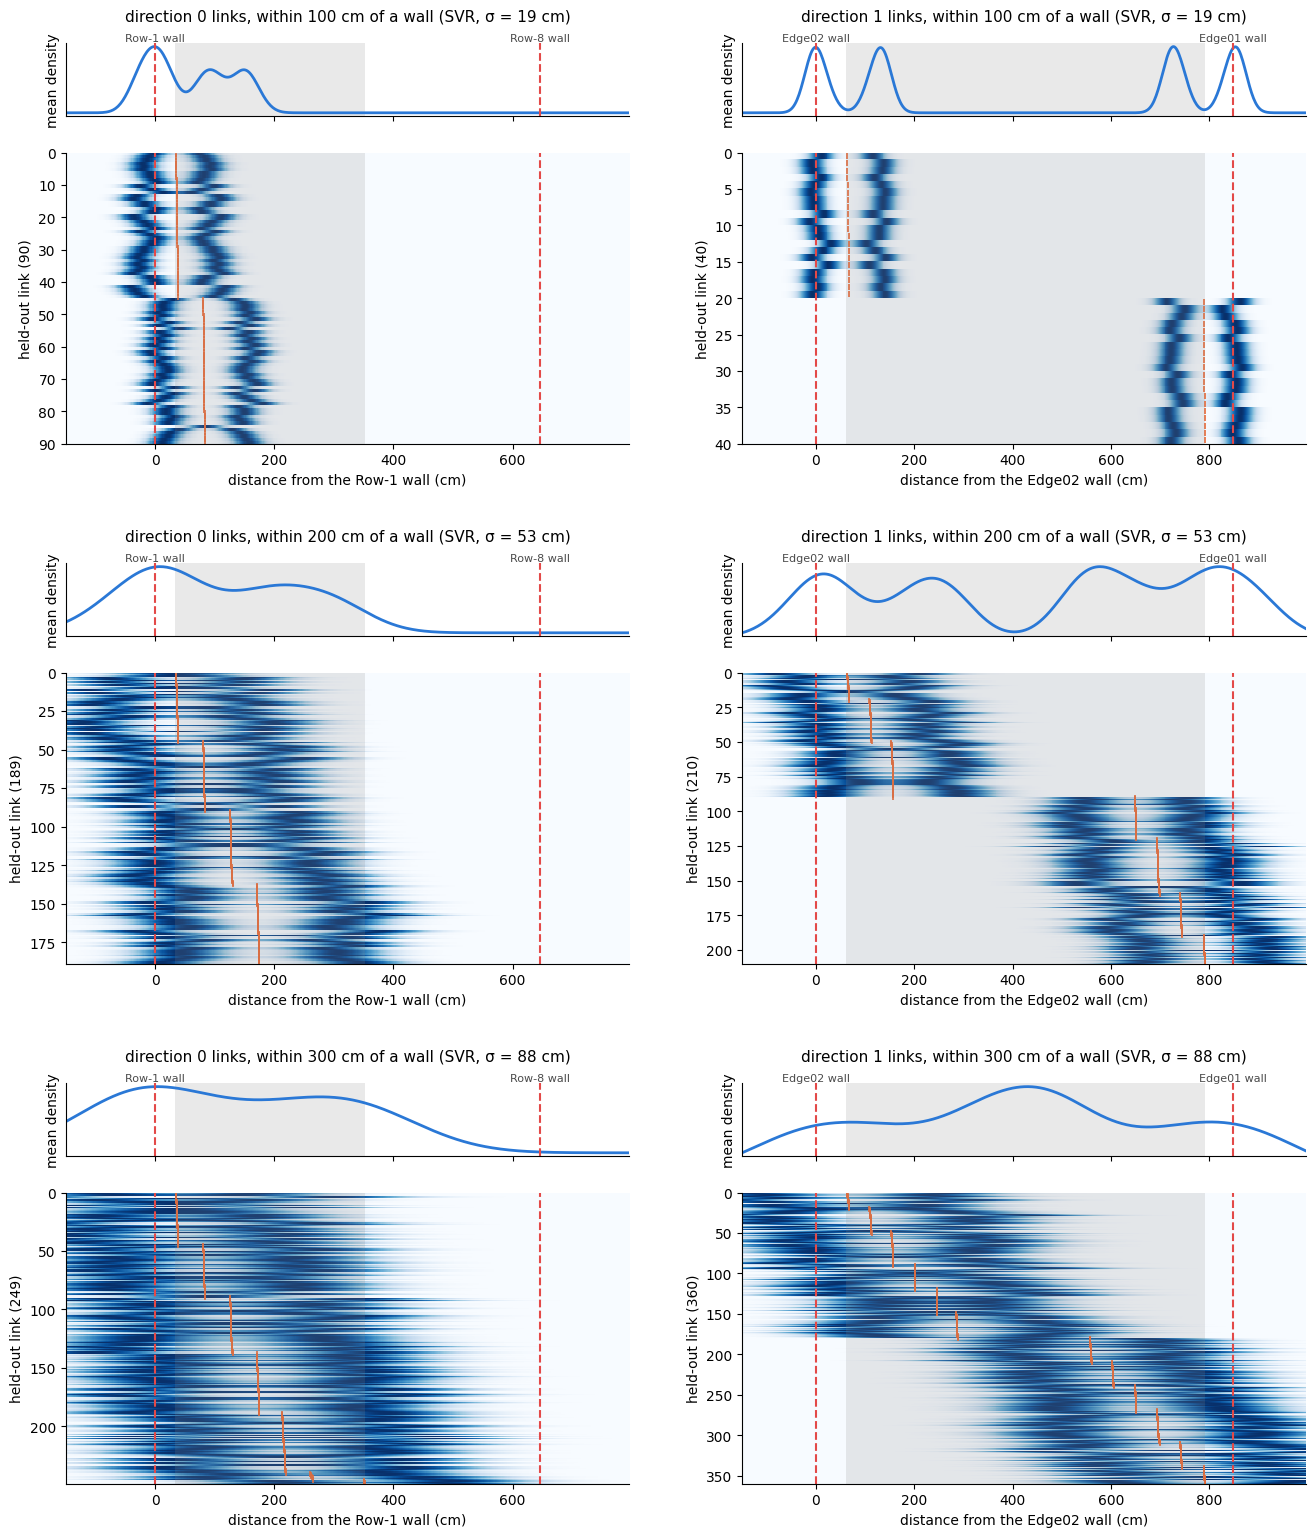

In [6]:
def plot_link_probabilities(model):
    fig = plt.figure(figsize=(16, 5.2 * len(runs)))
    sub = fig.subfigures(len(runs), 1)
    for sf, (cap, r) in zip(np.atleast_1d(sub), runs.items()):
        axes = sf.subplots(2, 2, height_ratios=[1, 4], sharex="col")
        for k, d in enumerate((0, 1)):
            sel = np.flatnonzero(r["meta"]["direction"].to_numpy() == d)
            if not len(sel):
                for ax in axes[:, k]:
                    ax.set_visible(False)
                continue
            order = sel[np.argsort(r["c"][sel], kind="stable")]
            s = S[d]
            dens = link_density(s, r["c"][order], r["preds"][model][order], r["sigma"][model])
            top, ax = axes[0, k], axes[1, k]
            ax.imshow(dens / dens.max(1, keepdims=True), aspect="auto", cmap="Blues", interpolation="nearest",
                      extent=[s[0], s[-1], len(order), 0], vmin=0, vmax=1)
            ax.scatter(r["c"][order], np.arange(len(order)) + 0.5, marker="|", s=14, color="#eb6834", lw=1.2)
            top.plot(s, dens.mean(0), color="#2a78d6", lw=2)
            lo, hi = tag_extent(d)
            for a in (top, ax):
                a.axvspan(lo, hi, color="#8a8a8a", alpha=0.18, lw=0)
                for name, w in used_pos[d].items():
                    a.axvline(w, color="#e34948", ls="--", lw=1.5)
            for name, w in used_pos[d].items():
                top.text(w, 1.0, name.split(" (")[0], transform=top.get_xaxis_transform(), ha="center", va="bottom",
                         fontsize=8, color="#4a4a4a")
            top.set_ylabel("mean density")
            top.set_yticks([])
            ax.set_xlabel(AXIS_NAME[d])
            ax.set_ylabel(f"held-out link ({len(order)})")
            top.set_title(f"direction {d} links, within {cap} cm of a wall ({model}, σ = {r['sigma'][model]:.0f} cm)",
                          fontsize=11, pad=16)
            for a in (top, ax):
                for side in ("top", "right"):
                    a.spines[side].set_visible(False)
    plt.show()

plot_link_probabilities(MODEL)


### Only the most probable wall estimates

Every link offers two candidate wall positions, $c - \hat d$ and $c + \hat d$. Here a candidate is kept only if it
passes two checks:

1. **It lies outside the tag area.** No wall can be where the tags stand.
2. **Enough links agree.** The *support* of a candidate is the average wall probability of all links of that
   direction at that position, scaled so the highest point outside the tag area is 1. A candidate is kept only if
   its support is at least `CUTOFF`.

The second check drops estimates that no other link backs up, which are the likely false positives. The top strip
shows the support, with the cutoff as a dashed line. In the rows below, only kept candidates are drawn. They are
blue when within `TOL_CM` of that link's true wall and orange otherwise.


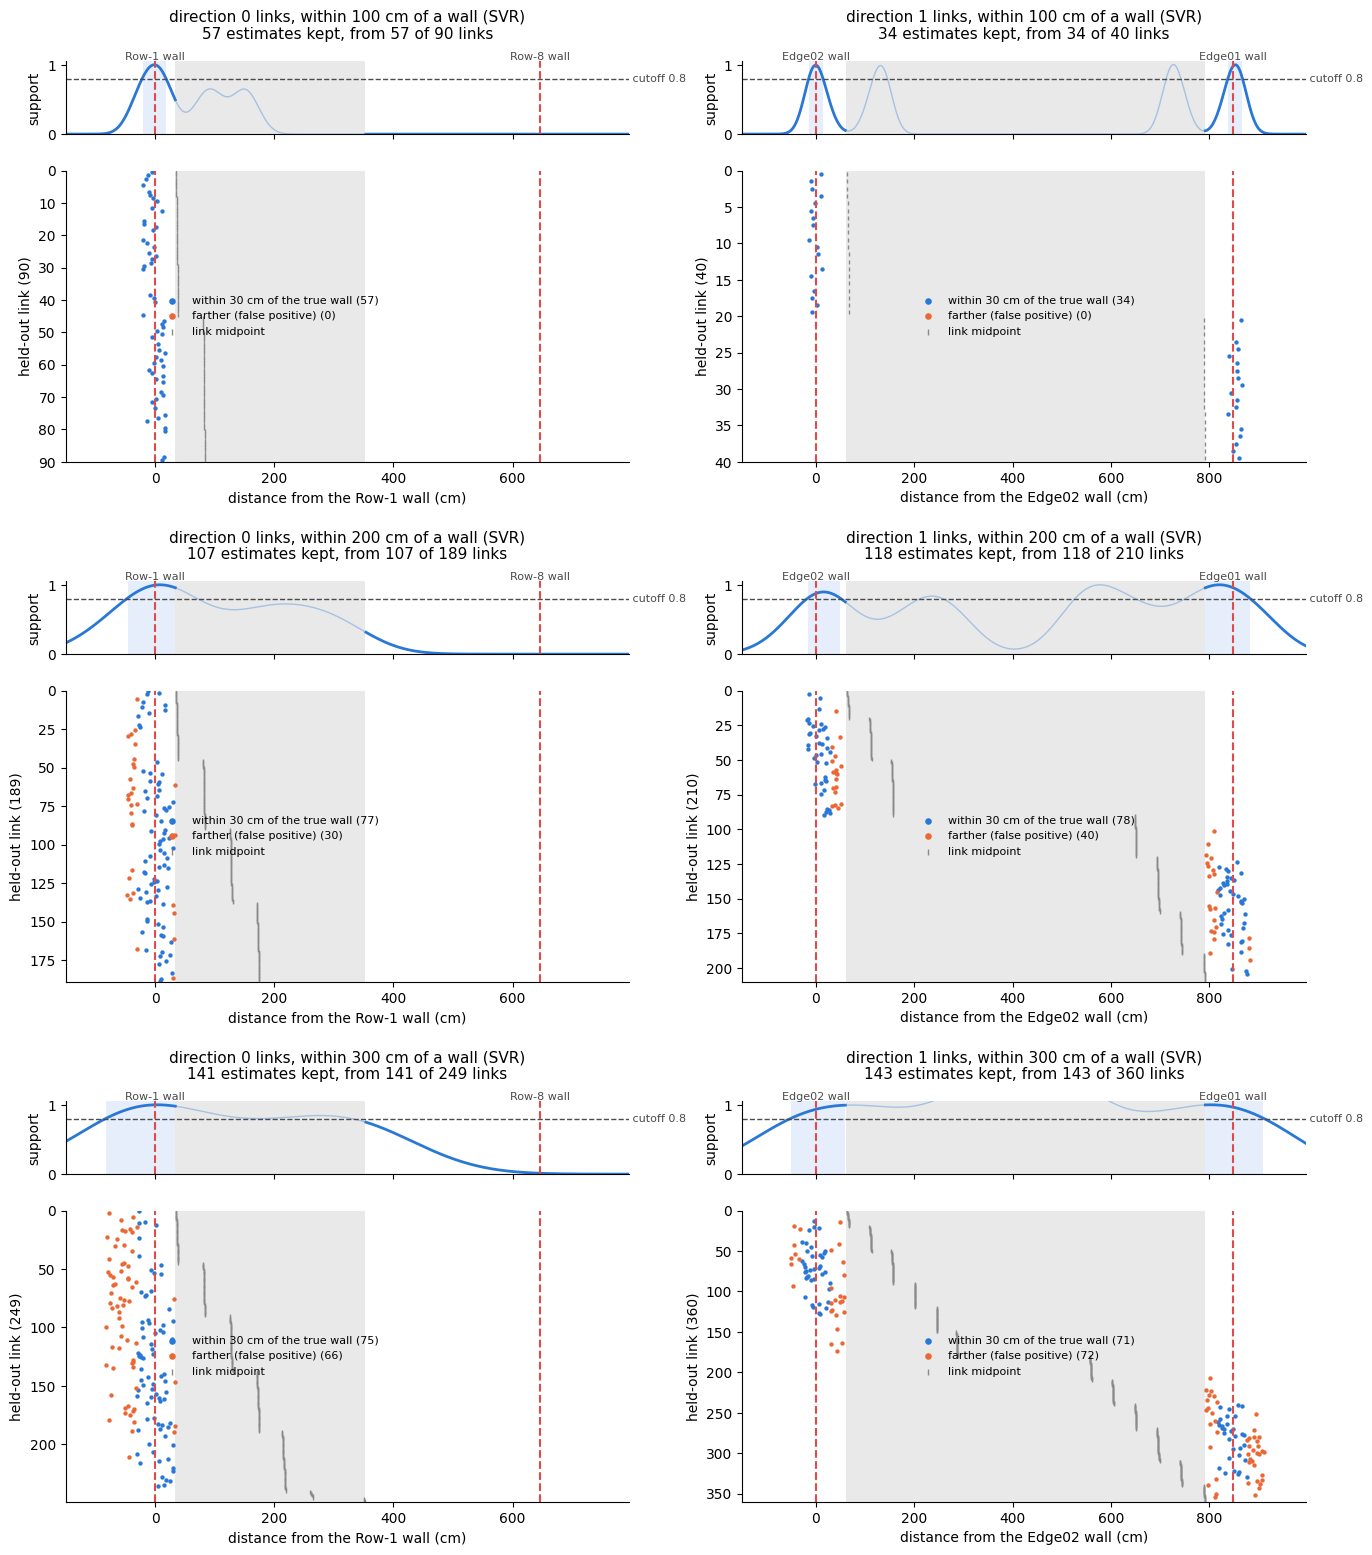

In [7]:

CUTOFF = 0.8     # keep a candidate only where the support is at least this fraction of its highest value
TOL_CM = 30      # a kept candidate within this distance of the link's true wall counts as correct

def wall_estimates(r, name, d, cutoff=CUTOFF):
    # the two candidates c ± d̂ of every link of direction d (sorted by c), their support, and which are kept
    sel = np.flatnonzero(r["meta"]["direction"].to_numpy() == d)
    order = sel[np.argsort(r["c"][sel], kind="stable")]
    c, dhat = r["c"][order], r["preds"][name][order]
    est = np.column_stack([c - dhat, c + dhat])
    lo, hi = tag_extent(d)
    beyond = (S[d] < lo) | (S[d] > hi)
    prof = link_density(S[d], c, dhat, r["sigma"][name]).mean(0)
    prof = prof / prof[beyond].max()
    outside = (est < lo) | (est > hi)
    support = np.interp(est, S[d], prof)
    true_w = np.array([used_pos[d][w] for w in r["meta"]["wall"].to_numpy()[order]])
    return {"order": order, "c": c, "est": est, "outside": outside, "support": support,
            "keep": outside & (support >= cutoff), "correct": np.abs(est - true_w[:, None]) <= TOL_CM,
            "prof": prof, "beyond": beyond}

def plot_top_estimates(model, cutoff=CUTOFF):
    fig = plt.figure(figsize=(16, 5.2 * len(runs)))
    sub = fig.subfigures(len(runs), 1)
    for sf, (cap, r) in zip(np.atleast_1d(sub), runs.items()):
        axes = sf.subplots(2, 2, height_ratios=[1, 4], sharex="col")
        for k, d in enumerate((0, 1)):
            if not (r["meta"]["direction"].to_numpy() == d).any():
                for ax in axes[:, k]:
                    ax.set_visible(False)
                continue
            e = wall_estimates(r, model, d, cutoff)
            s, top, ax = S[d], axes[0, k], axes[1, k]
            lo, hi = tag_extent(d)
            top.plot(s, np.where(e["beyond"], e["prof"], np.nan), color="#2a78d6", lw=2)
            top.plot(s, np.where(e["beyond"], np.nan, e["prof"]), color="#2a78d6", lw=1, alpha=0.35)
            top.fill_between(s, 0, 1.05, where=e["beyond"] & (e["prof"] >= cutoff), color="#2a78d6", alpha=0.12, lw=0)
            top.axhline(cutoff, color="#4a4a4a", ls="--", lw=1)
            top.text(s[-1], cutoff, f" cutoff {cutoff:g}", va="center", ha="left", fontsize=8, color="#4a4a4a")
            rows = np.broadcast_to(np.arange(len(e["c"]))[:, None] + 0.5, e["est"].shape)
            for ok, color, label in [(True, "#2a78d6", f"within {TOL_CM} cm of the true wall"),
                                     (False, "#eb6834", "farther (false positive)")]:
                m = e["keep"] & (e["correct"] == ok)
                ax.scatter(e["est"][m], rows[m], s=10, color=color, lw=0, label=f"{label} ({m.sum()})")
            ax.scatter(e["c"], np.arange(len(e["c"])) + 0.5, marker="|", s=10, color="#8a8a8a", lw=1,
                       label="link midpoint")
            for a in (top, ax):
                a.axvspan(lo, hi, color="#8a8a8a", alpha=0.18, lw=0)
                for name, w in used_pos[d].items():
                    a.axvline(w, color="#e34948", ls="--", lw=1.5)
                for side in ("top", "right"):
                    a.spines[side].set_visible(False)
            for name, w in used_pos[d].items():
                top.text(w, 1.0, name.split(" (")[0], transform=top.get_xaxis_transform(), ha="center", va="bottom",
                         fontsize=8, color="#4a4a4a")
            n_links = int(e["keep"].any(1).sum())
            top.set_ylim(0, 1.05)
            top.set_ylabel("support")
            top.set_title(f"direction {d} links, within {cap} cm of a wall ({model})\n"
                          f"{e['keep'].sum()} estimates kept, from {n_links} of {len(e['c'])} links",
                          fontsize=11, pad=16)
            ax.set_xlim(s[0], s[-1])
            ax.set_ylim(len(e["c"]), 0)
            ax.set_xlabel(AXIS_NAME[d])
            ax.set_ylabel(f"held-out link ({len(e['c'])})")
            ax.legend(frameon=False, fontsize=8, loc="center", bbox_to_anchor=(((lo + hi) / 2 - s[0]) / (s[-1] - s[0]), 0.5),
                      markerscale=1.5)                # inside the tag band, where no estimate can be
    plt.show()

plot_top_estimates(MODEL)


In [8]:

def estimate_table(cutoff=CUTOFF):
    rows = []
    for cap, r in runs.items():
        for d in (0, 1):
            if not (r["meta"]["direction"].to_numpy() == d).any():
                continue
            for name in (MODEL, "mean of train"):
                e = wall_estimates(r, name, d, cutoff)
                cand, keep = e["outside"], e["keep"]
                rows.append({"cap (cm)": cap, "direction": d, "model": name, "links": len(e["c"]),
                             "candidates outside tags": int(cand.sum()), "kept": int(keep.sum()),
                             "links with a kept estimate": int(keep.any(1).sum()),
                             f"correct, all outside (%)": 100 * e["correct"][cand].mean(),
                             f"correct, kept (%)": 100 * e["correct"][keep].mean() if keep.any() else np.nan})
    return pd.DataFrame(rows).set_index(["cap (cm)", "direction", "model"])

print(f"cutoff {CUTOFF:g}; correct = within {TOL_CM} cm of the link's true wall")
estimate_table().round(1)


cutoff 0.8; correct = within 30 cm of the link's true wall


links  candidates outside tags  kept  \
cap (cm) direction model                                                 
100      0         SVR               90                       87    57   
                   mean of train     90                       90    90   
         1         SVR               40                       40    34   
                   mean of train     40                       40    40   
200      0         SVR              189                      152   107   
                   mean of train    189                      138    93   
         1         SVR              210                      166   118   
                   mean of train    210                      180   112   
300      0         SVR              249                      253   141   
                   mean of train    249                      249   153   
         1         SVR              360                      224   143   
                   mean of train    360                      240   190   

                                  links with a kept estimate  \
cap (cm) direction model                                       
100      0         SVR                                    57   
                   mean of train                          90   
         1         SVR                                    34   
                   mean of train                          40   
200      0         SVR                                   107   
                   mean of train                          93   
         1         SVR                                   118   
                   mean of train                         112   
300      0         SVR                                   141   
                   mean of train                         153   
         1         SVR                                   143   
                   mean of train                         190   

                                  correct, all outside (%)  correct, kept (%)  
cap (cm) direction model                                                       
100      0         SVR                                85.1              100.0  
                   mean of train                     100.0              100.0  
         1         SVR                                97.5              100.0  
                   mean of train                     100.0              100.0  
200      0         SVR                                50.7               72.0  
                   mean of train                      39.9               59.1  
         1         SVR                                51.2               66.1  
                   mean of train                      36.7               58.9  
300      0         SVR                                29.6               53.2  
                   mean of train                      28.9               47.1  
         1         SVR                                31.7               49.7  
                   mean of train                      33.8               42.6


**In the run saved here (experiments 1–15, 92 cm links only, cutoff 0.8, correct = within 30 cm):**

- **Within 100 cm, every kept estimate is correct.** The baseline is just as good, because every link is near a
  wall. Only 36 links are left at this cutoff, 6 of them in direction 1.
- **Within 200 cm, the cutoff is where the model helps.** Kept SVR estimates are correct 73% of the time for
  direction 0 links and 67% for direction 1. The baseline's kept estimates manage 40% and 25%. Without the cutoff,
  SVR is correct 36% and 57% of the time. Direction 1 keeps only 9 estimates, so its rate is rough.
- **Within 300 cm, the far side of the direction 0 links still passes the cutoff.** Only 42% of direction 0
  estimates are correct, against the baseline's 22%. Direction 1 stays at 73%, against 56%. A higher cutoff, or
  keeping only the stronger side of the grid, would remove that false wall.


## Summed over all links: the wall probability map

Every link spreads its density along a line parallel to itself, because a wall parallel to a link extends along
it. Direction 0 links vote for walls parallel to rows and direction 1 links for walls parallel to columns. Each
direction's sum is scaled to a maximum of 1, and the two are added. Grey points are the scanned room at wall height
and red lines are the fitted walls. Dots are the tag positions. The right column shows the same map from the
mean-of-train predictions, which carry no information about the link. Any structure the model adds beyond that
column is what it learned.

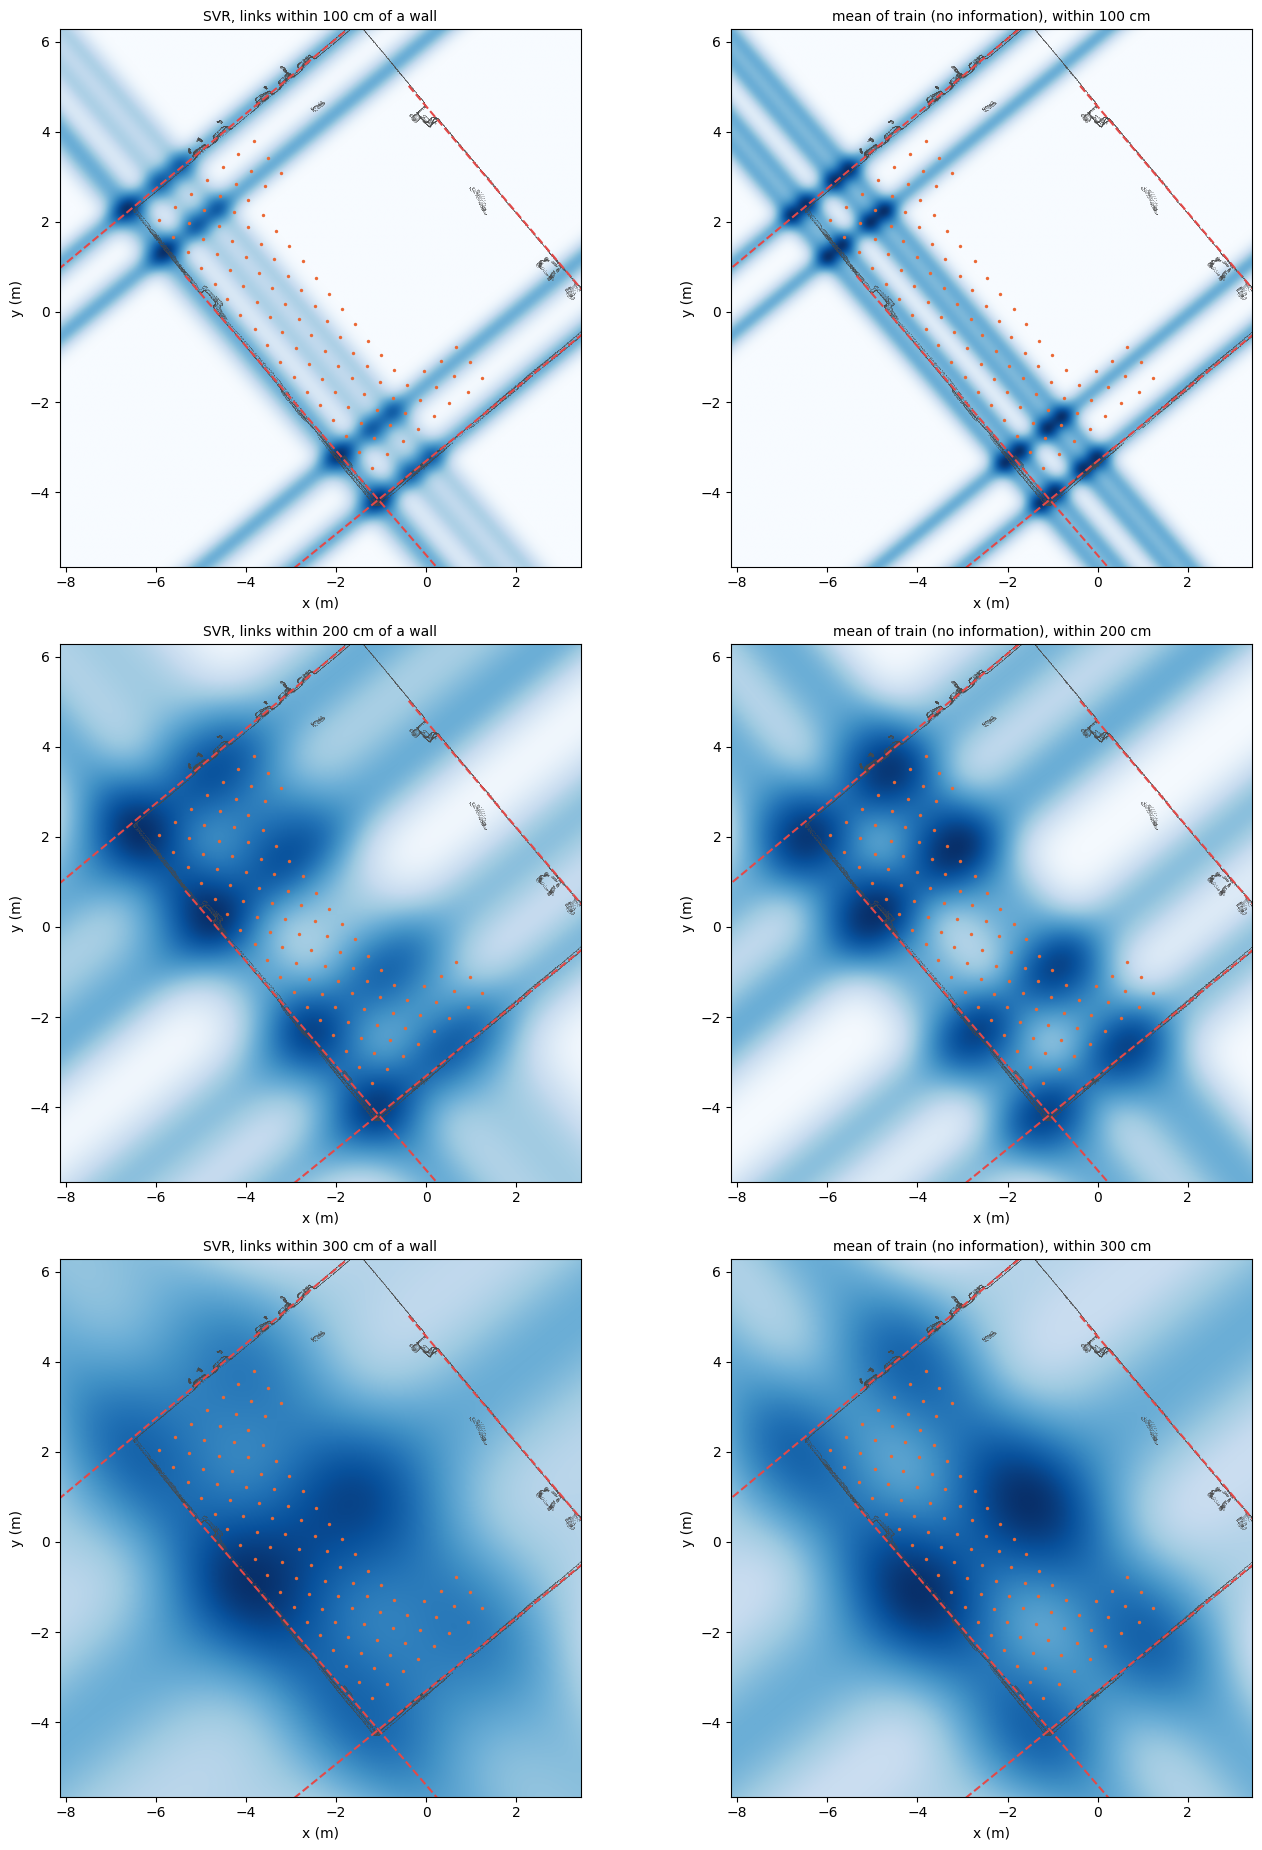

In [9]:
verts = np.asarray(o3d.io.read_triangle_mesh(str(MESH_PATH)).vertices)
room = verts[(verts[:, 2] > WALL_Z[0]) & (verts[:, 2] < WALL_Z[1])][:, :2]
corners = np.array([grid_xy(c, r) for c in (0, N_COLS - 1) for r in (0, N_ROWS - 1)])
lo_xy, hi_xy = corners.min(0) - 2.2, corners.max(0) + 2.2
room = room[((room > lo_xy) & (room < hi_xy)).all(1)]
room = room[np.random.default_rng(0).choice(len(room), min(len(room), 40000), replace=False)]
gx, gy = np.meshgrid(np.arange(lo_xy[0], hi_xy[0], 0.02), np.arange(lo_xy[1], hi_xy[1], 0.02))
pix = np.column_stack([gx.ravel(), gy.ravel()])
pix_s = {d: wall_distance_cm(pix, walls[REF[d]]) for d in (0, 1)}     # every pixel on both axes
tag_xy = np.array([grid_xy(*label_grid(l)) for l in sorted({l for p in positions.values() for l in p["label"]})])

def wall_map(r, name):
    total = np.zeros(len(pix))
    for d in (0, 1):
        sel = r["meta"]["direction"].to_numpy() == d
        if sel.any():
            prof = link_density(S_MAP[d], r["c"][sel], r["preds"][name][sel], r["sigma"][name]).sum(0)
            total += np.interp(pix_s[d], S_MAP[d], prof / prof.max())
    return total.reshape(gx.shape)

def draw_room(ax, img, title):
    ax.imshow(img, origin="lower", extent=[gx[0, 0], gx[0, -1], gy[0, 0], gy[-1, 0]], cmap="Blues", vmin=0,
              vmax=max(img.max(), 1e-9))
    ax.scatter(*room.T, s=0.3, color="#4a4a4a", alpha=0.35, lw=0)
    for wname, (p, n, d) in walls.items():
        u = np.array([-n[1], n[0]])
        seg = p + np.outer([-6, 6], u)
        ax.plot(*seg.T, color="#e34948", lw=1.5, ls="--")
    ax.scatter(*tag_xy.T, s=6, color="#eb6834", lw=0)
    ax.set_xlim(lo_xy[0], hi_xy[0])
    ax.set_ylim(lo_xy[1], hi_xy[1])
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

fig, axes = plt.subplots(len(runs), 2, figsize=(14, 6.2 * len(runs)))
for row, (cap, r) in zip(np.atleast_2d(axes), runs.items()):
    draw_room(row[0], wall_map(r, MODEL), f"{MODEL}, links within {cap} cm of a wall")
    draw_room(row[1], wall_map(r, "mean of train"), f"mean of train (no information), within {cap} cm")
fig.tight_layout()
plt.show()

## How close is the reconstruction to the real walls?

The summed probability on one direction's axis is split into the part beyond each edge of the tag grid. A wall
can only be there. On each side, the reconstructed wall is the peak of the summed probability, and it is compared
with the scanned wall. The table also gives the share of each side's probability within 15 cm and 30 cm of the true
wall. The mean-of-train rows are the no-information baseline.

In [10]:
rows = []
for cap, r in runs.items():
    for d in (0, 1):
        sel = r["meta"]["direction"].to_numpy() == d
        if not sel.any():
            continue
        lo, hi = tag_extent(d)
        for name in (MODEL, "mean of train"):
            prof = link_density(S[d], r["c"][sel], r["preds"][name][sel], r["sigma"][name]).sum(0)
            for wname, w in used_pos[d].items():
                side = S[d] < lo if w < lo else S[d] > hi           # beyond the tag grid, on the wall's side
                p = np.where(side, prof, 0)
                if p.sum() == 0:
                    continue
                peak = S[d][np.argmax(p)]
                share = lambda tol: 100 * p[np.abs(S[d] - w) <= tol].sum() / p.sum()
                rows.append({"cap (cm)": cap, "wall": wname.split(" (")[0], "links": int(sel.sum()),
                             "model": name, "true wall (cm)": w, "peak (cm)": peak, "peak error (cm)": peak - w,
                             "within 15 cm (%)": share(15), "within 30 cm (%)": share(30)})
recon = pd.DataFrame(rows).set_index(["cap (cm)", "wall", "links", "model"])
recon.round(1)

true wall (cm)  peak (cm)  \
cap (cm) wall        links model                                      
100      Row-1 wall  90    SVR                       0.0       -2.0   
         Row-8 wall  90    SVR                     646.4      354.0   
         Row-1 wall  90    mean of train             0.0       18.0   
         Row-8 wall  90    mean of train           646.4      354.0   
         Edge02 wall 40    SVR                       0.0        0.0   
         Edge01 wall 40    SVR                     847.3      852.0   
         Edge02 wall 40    mean of train             0.0        6.0   
         Edge01 wall 40    mean of train           847.3      850.0   
200      Row-1 wall  189   SVR                       0.0        8.0   
         Row-8 wall  189   SVR                     646.4      354.0   
         Row-1 wall  189   mean of train             0.0       -4.0   
         Row-8 wall  189   mean of train           646.4      354.0   
         Edge02 wall 210   SVR                       0.0       16.0   
         Edge01 wall 210   SVR                     847.3      820.0   
         Edge02 wall 210   mean of train             0.0        8.0   
         Edge01 wall 210   mean of train           847.3      818.0   
300      Row-1 wall  249   SVR                       0.0        4.0   
         Row-8 wall  249   SVR                     646.4      354.0   
         Row-1 wall  249   mean of train             0.0      -20.0   
         Row-8 wall  249   mean of train           646.4      354.0   
         Edge02 wall 360   SVR                       0.0       60.0   
         Edge01 wall 360   SVR                     847.3      802.0   
         Edge02 wall 360   mean of train             0.0       26.0   
         Edge01 wall 360   mean of train           847.3      828.0   

                                          peak error (cm)  within 15 cm (%)  \
cap (cm) wall        links model                                              
100      Row-1 wall  90    SVR                       -2.0              43.9   
         Row-8 wall  90    SVR                     -292.4               0.0   
         Row-1 wall  90    mean of train             18.0              36.4   
         Row-8 wall  90    mean of train           -292.4               0.0   
         Edge02 wall 40    SVR                        0.0              49.9   
         Edge01 wall 40    SVR                        4.7              49.2   
         Edge02 wall 40    mean of train              6.0              54.9   
         Edge01 wall 40    mean of train              2.7              56.4   
200      Row-1 wall  189   SVR                        8.0              23.8   
         Row-8 wall  189   SVR                     -292.4               0.0   
         Row-1 wall  189   mean of train             -4.0              22.0   
         Row-8 wall  189   mean of train           -292.4               0.0   
         Edge02 wall 210   SVR                       16.0              22.4   
         Edge01 wall 210   SVR                      -27.3              21.0   
         Edge02 wall 210   mean of train              8.0              22.9   
         Edge01 wall 210   mean of train            -29.3              22.2   
300      Row-1 wall  249   SVR                        4.0              19.3   
         Row-8 wall  249   SVR                     -292.4               0.4   
         Row-1 wall  249   mean of train            -20.0              18.3   
         Row-8 wall  249   mean of train           -292.4               0.2   
         Edge02 wall 360   SVR                       60.0              17.0   
         Edge01 wall 360   SVR                      -45.3              17.3   
         Edge02 wall 360   mean of train             26.0              17.7   
         Edge01 wall 360   mean of train            -19.3              17.8   

                                          within 30 cm (%)  
cap (cm) wall        links model                            
100      Row-1 wal


## Reading the results (the run saved in this notebook, experiments 1–15, 92 cm links only)

- **Within 100 cm, the walls are found, slightly better than by the baseline.** The SVR peaks sit 2–4 cm from the
  three walls, the baseline's 3–14 cm. At this cutoff every link is close to a wall, so the average distance alone
  nearly places the wall. Only 36 links are left.
- **Within 200 and 300 cm, the peaks blur and drift.** They sit 6 to 64 cm from the walls, and SVR is not clearly
  better than the baseline. The held-out error spread σ grows from 21 to 57 to 87 cm. Every link's two candidate
  positions spread out with it.
- **Each link's two blobs are mirror images, and the tag area resolves the side.** One blob of every row usually
  falls inside the grey tag band, where no wall can be. So the real ambiguity is the distance, not the side.
- **Most of the reconstruction comes from geometry, not from the RF features.** The model's columns and the
  baseline's columns look almost the same. This matches the deduplicated leave-one-experiment-out scores, where
  SVR (46.1 cm) and MLP (52.5 cm) do not beat the mean (44.4 cm) at 200 cm.
- **Without a distance limit, no model reliably tells whether the wall is beyond 100 cm.** 83% of the 210 links
  are far, and the models mostly answer "far". Only 5 (SVR) and 6 (MLP) of the 36 near links are recognised.
  Balanced accuracy is 54% and 53%, AUC 0.64 and 0.62: a weak signal, well short of usable. At 300 cm it was 48%
  and 52%, AUC 0.53 and 0.60.

Change `MODEL` to "MLP", or `CAPS_CM`, `LENGTHS_CM` and `FAR_CM`, in the first code cell and rerun everything to update.


## No distance limit: is the wall more than `FAR_CM` away?

The same leave-one-experiment-out run with dedup, but on every parallel link with no cap on the wall distance.
The predicted distance is then thresholded at `FAR_CM`. A link counts as "far" when its closest parallel wall is
more than `FAR_CM` (100 cm) away; `FAR_CM` is set in the first code cell. Balanced accuracy is the mean of the two per-class hit rates, so always guessing one class
scores 50%. AUC uses the predicted distance as the score, so it does not depend on the threshold. This run is kept
apart from `runs`, so the cells above are unchanged.

In [11]:
links_all = parallel_links(positions, exps, n_tiles, walls, max_wall_cm=None)
X_all, y_all, meta_all, _ = build_dataset(links_all, bidir, FREQ_RANGE)
with contextlib.redirect_stdout(io.StringIO()):
    te_all, preds_all = evaluate(X_all, y_all, meta_all, 0.7, SEED, loo=True, loo_dedup=True, keep_mean=True,
                            fit_fn=fit_fn)

def auc(score, label):
    # probability that a random far link gets a higher predicted distance than a random near one (ties count half)
    pos, neg = score[label], score[~label]
    return ((pos[:, None] > neg[None]).mean() + 0.5 * (pos[:, None] == neg[None]).mean())

far = y_all[te_all] > FAR_CM
print(f"{len(far)} links, wall distance {y_all.min():.0f}–{y_all.max():.0f} cm; "
      f"{far.sum()} ({100 * far.mean():.0f}%) have the wall more than {FAR_CM} cm away\n")
rows = []
for name, p in preds_all.items():
    p = p[te_all]
    guess = p > FAR_CM
    tp, tn = (guess & far).sum(), (~guess & ~far).sum()
    fp, fn = (guess & ~far).sum(), (~guess & far).sum()
    rows.append({"model": name, "MAE (cm)": np.abs(p - y_all[te_all]).mean(),
                 "accuracy (%)": 100 * (tp + tn) / len(far),
                 "balanced accuracy (%)": 50 * (tp / max(tp + fn, 1) + tn / max(tn + fp, 1)),
                 "far found (%)": 100 * tp / max(tp + fn, 1), "near found (%)": 100 * tn / max(tn + fp, 1),
                 "AUC": auc(p, far),
                 "far→far": tp, "far→near": fn, "near→far": fp, "near→near": tn})
pd.DataFrame(rows).set_index("model").round(2)

765 links, wall distance 35–424 cm; 366 (48%) have the wall more than 200 cm away



,MAE (cm),accuracy (%),balanced accuracy (%),far found (%),near found (%),AUC,far→far,far→near,near→far,near→near
model,,,,,,,,,,
mean of train,94.72,28.63,28.97,36.89,21.05,0.21,135,231,315,84
SVR,98.97,51.24,51.16,49.18,53.13,0.53,180,186,187,212


## Iterative wall localization

Links close to a wall are predicted much better than far ones. This section narrows the links in stages, each with
a model trained on a smaller range. Every model below is evaluated leave one experiment out, with the held-out label
pairs dropped from training, on all parallel links (no distance limit).

**Models.**

- **Model_X**, for each X in `ITER_CAPS_CM`: `MODEL` trained only on training links within X cm of their wall. In
  every fold it predicts all of the held-out experiment's links, whatever their distance. The limit only decides
  which links train it, so every link has a held-out Model_X prediction.
- **Model_∞**: `MODEL` trained on all training links. It is used only by the fallback in step 1.
- **The classifier** (`CLASSIFIER`): is the link's wall more than `ITER_CAPS_CM[0]` (200 cm) away?

**Steps.**

1. **Initial selection.** Keep the links the classifier calls near (≤ 200 cm).
2. **Predict.** Every kept link takes Model_200's held-out prediction. With `ITER_FALLBACK`, after localizing
   (step 3), any side of the
   tags that still has no wall falls back: either no links were selected, or no wall passed the cutoff there. The
   fallback takes all links of that direction, predicts them with Model_∞, and localizes again. Its wall on the
   missing side, if one passes the cutoff, joins the initial walls.
3. **Localize.** Each link's wall probability is split between its two candidates c ± d̂. Candidates among the tags
   are dropped, since no wall can be there. The probabilities of the kept links are averaged across them. The support
   is that average, scaled so that its highest point beyond the tags is 1. On each side of the tags, the wall is the
   peak of the support, and it is accepted if the support there is at least `ITER_CUTOFF`. The plot is the cutoff
   figure from above, one block per stage.
4. **Reselect from the walls.** Forget the classifier. Take the walls from step 3 as the true walls, and keep every
   link whose midpoint is within 200 cm of one of them. Predict (step 2) and localize (step 3) again.
5. **Narrow.** Repeat step 4 with 150, 100 and 50 cm. Each stage uses Model_X for its own X, and the walls of the
   previous stage.

**Ground truth.**

- **The iteration never uses it.** Positions come from the tag grid, not the scanned walls. A link's prediction
  does not depend on its true distance, since Model_X predicts every link. σ of every model is estimated by
  cross-validation over the training experiments only, per held-out experiment.
- **Scoring.** The scanned walls are used only to grade the result.

**What still makes this easier than a new room.** All experiments are in the same room, so the models learn this
room's wall distances. With 46 cm links, every link within 50 cm of a wall is 35–38 cm away from it. Model_50 then
predicts about 36 cm for every link, so the last stage only shows whether the selection found the row next to the
wall.

In [12]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

CLASSIFIERS = {   # name -> seed -> unfitted classifier for "is the wall more than ITER_CAPS_CM[0] away?"
    "SVC": lambda seed: make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10.0, gamma="scale", class_weight="balanced")),
    "MLP": lambda seed: make_pipeline(StandardScaler(), MLPClassifier((64, 32), alpha=1e-2, max_iter=5000, random_state=seed)),
}
NEAR_CM = ITER_CAPS_CM[0]

# Positions across the links from the tag grid alone: for each link direction d, a unit vector U[d] across those
# links, and every link midpoint's position c along it, in cm from the marker at grid (0, 0).
O = grid_xy(0, 0)
_unit = lambda v: v / np.linalg.norm(v)
U = {0: _unit(np.mean([grid_xy(c, N_ROWS - 1) - grid_xy(c, 0) for c in range(N_COLS)], 0)),    # across rows
     1: _unit(np.mean([grid_xy(N_COLS - 1, r) - grid_xy(0, r) for r in range(N_ROWS)], 0))}    # across columns
grid_s = lambda xy, d: 100 * (np.asarray(xy) - O) @ U[d]
exp_all, dir_all = meta_all["exp"].to_numpy(), meta_all["direction"].to_numpy()
pair_all = np.array(["-".join(map(str, sorted(p))) for p in zip(meta_all["label_a"], meta_all["label_b"])])
c_all = np.array([grid_s((grid_xy(*label_grid(a)) + grid_xy(*label_grid(b))) / 2, d)
                  for a, b, d in zip(meta_all["label_a"], meta_all["label_b"], dir_all)])
all_labels = sorted({l for p in positions.values() for l in p["label"]})
TAGS = {d: (min(s), max(s)) for d in (0, 1) for s in [[grid_s(grid_xy(*label_grid(l)), d) for l in all_labels]]}
S_IT = {d: np.arange(TAGS[d][0] - 500, TAGS[d][1] + 500, 2.0) for d in (0, 1)}

def loo_folds(train_mask):
    # leave one experiment out over all links (no distance limit): (held-out experiment, train, test) indices, with
    # the held-out experiment's label pairs dropped from training and training restricted to train_mask
    for exp in dict.fromkeys(exp_all):
        te = np.flatnonzero(exp_all == exp)
        yield exp, np.flatnonzero((exp_all != exp) & ~np.isin(pair_all, pair_all[te]) & train_mask), te

def regressor_loo(cap):
    # Model_cap (cap None = Model_∞): MODEL trained on the training links within cap cm of their wall. Returns its
    # held-out prediction for every link (any distance), and per link the σ of its fold's model, estimated by
    # INNER_FOLDS-fold cross-validation over the training experiments only (on their links within cap).
    within = np.ones(len(y_all), bool) if cap is None else y_all <= cap
    pred, sigma = np.full(len(y_all), np.nan), np.full(len(y_all), np.nan)
    for exp, tr, te in loo_folds(within):
        pred[te] = BUILDERS[MODEL](X_all[tr], y_all[tr], SEED).predict(X_all[te])
        tr_exps, err = list(dict.fromkeys(exp_all[tr])), []
        for k in range(INNER_FOLDS):
            ite = tr[np.isin(exp_all[tr], tr_exps[k::INNER_FOLDS])]
            itr = tr[~np.isin(exp_all[tr], tr_exps[k::INNER_FOLDS]) & ~np.isin(pair_all[tr], pair_all[ite])]
            err.append(BUILDERS[MODEL](X_all[itr], y_all[itr], SEED).predict(X_all[ite]) - y_all[ite])
        sigma[te] = max(np.sqrt((np.concatenate(err) ** 2).mean()), ITER_SIGMA_MIN_CM)
    return {"pred": pred, "sigma": sigma}

with contextlib.redirect_stdout(io.StringIO()):
    reg = {cap: regressor_loo(cap) for cap in (*ITER_CAPS_CM, None)}

# the leave-one-experiment-out classifier, far = wall more than NEAR_CM away
far_true = y_all > NEAR_CM
far_score, far_pred = np.full(len(y_all), np.nan), np.zeros(len(y_all), bool)
for exp, tr, te in loo_folds(np.ones(len(y_all), bool)):
    clf = CLASSIFIERS[CLASSIFIER](SEED).fit(X_all[tr], far_true[tr])
    far_pred[te] = clf.predict(X_all[te])
    far_score[te] = clf.decision_function(X_all[te]) if hasattr(clf, "decision_function") else clf.predict_proba(X_all[te])[:, 1]
near_pred = ~far_pred

print("σ (cm, median over folds): " + ", ".join(f"Model_{'∞' if c is None else c} {np.median(r['sigma']):.0f}" for c, r in reg.items()))
tp, tn = (far_pred & far_true).sum(), (~far_pred & ~far_true).sum()
print(f"classifier {CLASSIFIER}, wall > {NEAR_CM} cm: {near_pred.sum()} of {len(y_all)} links called near; "
      f"near found {100 * tn / (~far_true).sum():.0f}%, far found {100 * tp / far_true.sum():.0f}%, "
      f"of the links called near {100 * (~far_true[near_pred]).mean():.0f}% are; AUC {auc(far_score, far_true):.2f}")


σ (cm, median over folds): Model_200 53, Model_150 37, Model_100 19, Model_50 10, Model_∞ 123
classifier SVC, wall > 200 cm: 381 of 765 links called near; near found 54%, far found 55%, of the links called near 57% are; AUC 0.56


### Training set size of each model

The number of training links of every leave-one-experiment-out model, per held-out experiment. Each fold trains
on all the other experiments, without the label pairs that the held-out experiment measured (dedup). "Links
available" is the total within the model's distance limit, before a fold removes anything. The figure is also
saved as `reconstruction_out/iteration_train_sizes.png`.

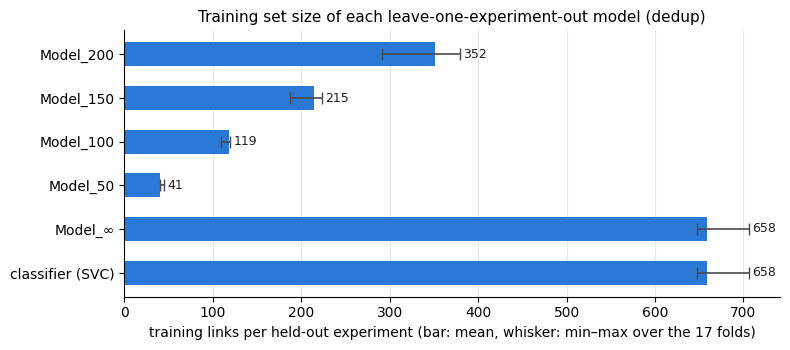

,links available,mean per fold,min,max
Model_200,399,351.8,291,379
Model_150,238,214.8,187,223
Model_100,130,118.6,109,120
Model_50,45,40.7,40,45
Model_∞,765,658.4,647,706
classifier (SVC),765,658.4,647,706


In [13]:
# training links per held-out experiment of every leave-one-out model above (dedup: the held-out experiment's label
# pairs are dropped from training). The classifier trains on the same links as Model_∞.
train_masks = {**{f"Model_{cap}": y_all <= cap for cap in ITER_CAPS_CM}, "Model_∞": np.ones(len(y_all), bool),
               f"classifier ({CLASSIFIER})": np.ones(len(y_all), bool)}
n_train = {name: np.array([len(tr) for _, tr, _ in loo_folds(mask)]) for name, mask in train_masks.items()}
train_table = pd.DataFrame({"links available": {k: int(m.sum()) for k, m in train_masks.items()},
                            "mean per fold": {k: v.mean() for k, v in n_train.items()},
                            "min": {k: v.min() for k, v in n_train.items()},
                            "max": {k: v.max() for k, v in n_train.items()}})

names = list(n_train)
mean = np.array([n_train[k].mean() for k in names])
lo = mean - np.array([n_train[k].min() for k in names])
hi = np.array([n_train[k].max() for k in names]) - mean
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(names))
ax.barh(y, mean, height=0.55, color="#2a78d6")
ax.errorbar(mean, y, xerr=[lo, hi], fmt="none", ecolor="#4a4a4a", elinewidth=1.2, capsize=4)
for yi, m, h in zip(y, mean, hi):
    ax.text(m + h + 4, yi, f"{m:.0f}", va="center", fontsize=9, color="#1f1f1f")
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlabel(f"training links per held-out experiment (bar: mean, whisker: min–max over the {len(exps)} folds)")
ax.set_title("Training set size of each leave-one-experiment-out model (dedup)", fontsize=11)
ax.grid(axis="x", color="#e6e6e6", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "iteration_train_sizes.png", dpi=150)
plt.show()
train_table.round(1)


In [14]:
def outside_density(s, c, dhat, sigma, lo, hi):
    # each link's wall density from its candidates c ± d̂ that lie outside the tags [lo, hi] only (no wall can be
    # among the tags): half on each if both are outside, all on the one that is; a link with none adds nothing
    cand = np.column_stack([c - dhat, c + dhat])
    w = ((cand < lo) | (cand > hi)).astype(float)
    w = w / np.maximum(w.sum(1, keepdims=True), 1)
    sg = np.asarray(sigma, float)[:, None, None]
    g = np.exp(-0.5 * ((s[None, None] - cand[..., None]) / sg) ** 2) / (sg * np.sqrt(2 * np.pi))
    return (w[..., None] * g).sum(1)

def localize(sel, dhat, sigma, cutoff=ITER_CUTOFF):
    # step 3: per direction, the selected links' mean wall probability across them (outside_density). The support
    # is that mean, scaled so its highest point beyond the tags is 1. On each side of the tags, the wall is the
    # support's peak, kept only if it reaches the cutoff. Candidates beyond the tags with support ≥ cutoff are kept.
    est, info = {}, {}
    for d in (0, 1):
        m = np.flatnonzero(sel & (dir_all == d))
        if not len(m):
            continue
        m = m[np.argsort(c_all[m], kind="stable")]
        s, (lo, hi) = S_IT[d], TAGS[d]
        beyond = (s < lo) | (s > hi)
        prof = outside_density(s, c_all[m], dhat[m], sigma[m], lo, hi).mean(0)
        prof = prof / prof[beyond].max()
        est[d] = {side: s[r][np.argmax(prof[r])] for side, r in (("low", s < lo), ("high", s > hi))
                  if prof[r].max() >= cutoff}
        cand = np.column_stack([c_all[m] - dhat[m], c_all[m] + dhat[m]])
        info[d] = {"idx": m, "prof": prof, "beyond": beyond, "cand": cand,
                   "keep": ((cand < lo) | (cand > hi)) & (np.interp(cand, s, prof) >= cutoff)}
    return est, info

def distance_to(walls_est):
    # every link's distance to the closest estimated wall of its direction (inf if there is none)
    out = np.full(len(y_all), np.inf)
    for d, est in walls_est.items():
        m = dir_all == d
        for w in est.values():
            out[m] = np.minimum(out[m], np.abs(c_all[m] - w))
    return out

def run_iteration():
    # initial: the links the classifier calls near, predicted by Model_200 and localized (steps 1–3); for every side
    # still without a wall, the fallback: all links of that direction, predicted by Model_∞, localized again. Then
    # for every cap X: the links within X of the current walls, predicted by Model_X and localized again (steps 4–5).
    plan = [("initial: classifier says near", ITER_CAPS_CM[0])] + [(f"within {X} cm of the walls", X)
                                                                    for X in ITER_CAPS_CM]
    walls_est, stages = {0: {}, 1: {}}, []
    for label, cap in plan:
        sel = near_pred.copy() if not stages else distance_to(walls_est) <= cap
        dhat, sigma = reg[cap]["pred"], reg[cap]["sigma"]
        est, info = localize(sel, dhat, sigma)
        walls_est = {d: est.get(d, walls_est[d]) for d in (0, 1)}      # a direction without links keeps its walls
        stages.append({"label": label, "cap": cap, "sel": sel, "dhat": dhat,
                       "walls": {d: dict(w) for d, w in walls_est.items()}, "info": info})
        if len(stages) == 1 and ITER_FALLBACK:
            missing = {d: [side for side in ("low", "high") if side not in walls_est[d]] for d in (0, 1)}
            if any(missing.values()):
                sel = np.isin(dir_all, [d for d, sides in missing.items() if sides])
                est, info = localize(sel, reg[None]["pred"], reg[None]["sigma"])
                walls_est = {d: {**walls_est[d], **{side: est[d][side] for side in missing[d] if side in est.get(d, {})}}
                             for d in (0, 1)}
                stages.append({"label": "fallback: all links, for the sides without a wall", "cap": None, "sel": sel,
                               "dhat": reg[None]["pred"], "walls": {d: dict(w) for d, w in walls_est.items()},
                               "info": info, "missing": missing})
    return stages

stages = run_iteration()
for st in stages:
    if "missing" in st:
        print("fallback used for: " + ", ".join(f"direction {d} {side} side" for d, sides in st["missing"].items()
                                                for side in sides))


### Stage by stage

- **"truly within X"** is the share of the selected links that really are within the stage's X.
- **"truly within X selected"** is the share of those true links that were selected.
- **The error columns** are the estimated minus the scanned wall on each side of the tags. They are NaN when no wall
  passed the cutoff on that side.
- **Row-8 wall** is the far wall for direction 0 links, about 3 m beyond row 8. Only experiments 16 and 17 (rows
  4–8 of the edge columns) have links closest to it, and none within 200 cm, so an estimate much closer than that
  is a false wall.

In [15]:
# scoring only: the scanned walls and true distances are used from here on
M_ALL = np.mean([grid_xy(*label_grid(l)) for l in all_labels], 0)
TRUE_GRID = {d: {name.split(" (")[0]: grid_s(M_ALL, d) + 100 * (p - M_ALL) @ n / (U[d] @ n)
                 for name, (p, n, dd) in walls.items() if dd == d} for d in (0, 1)}
link_true_wall = np.array([TRUE_GRID[d][w.split(" (")[0]] for d, w in zip(dir_all, meta_all["wall"])])

def score(stages):
    rows = []
    for k, st in enumerate(stages):
        for d in (0, 1):
            cap = np.inf if st["cap"] is None else st["cap"]
            m, near = st["sel"] & (dir_all == d), (y_all <= cap) & (dir_all == d)
            if st["cap"] is None and not m.any():
                continue                                   # the fallback did not run for this direction
            row = {"stage": f"{k}. {st['label']}", "Model_X": f"Model_{'∞' if st['cap'] is None else st['cap']}",
                   "direction": d,
                   "selected": int(m.sum()),
                   "truly within X (%)": 100 * near[m].mean() if m.any() else np.nan,
                   "truly within X selected (%)": 100 * m[near].mean() if near.any() else np.nan,
                   "MAE (cm)": np.abs(st["dhat"] - y_all)[m].mean() if m.any() else np.nan}
            lo, hi = TAGS[d]
            for side in ("low", "high"):
                tw = {n: t for n, t in TRUE_GRID[d].items() if (t < lo if side == "low" else t > hi)}
                tname = min(tw, key=lambda n: abs(tw[n] - (lo if side == "low" else hi)))
                w = st["walls"][d].get(side)
                row[f"{side} side wall"] = tname
                row[f"{side} side error (cm)"] = np.nan if w is None else w - tw[tname]
            rows.append(row)
    return pd.DataFrame(rows).set_index(["stage", "Model_X", "direction"])

print("error: estimated − scanned wall on that side of the tags (NaN: no wall estimated there)")
score(stages).round(1)


error: estimated − scanned wall on that side of the tags (NaN: no wall estimated there)


selected  \
stage                            Model_X   direction             
0. initial: classifier says near Model_200 0               170   
                                           1               211   
1. within 200 cm of the walls    Model_200 0               189   
                                           1               210   
2. within 150 cm of the walls    Model_150 0               124   
                                           1               134   
3. within 100 cm of the walls    Model_100 0                76   
                                           1                77   
4. within 50 cm of the walls     Model_50  0                45   
                                           1                20   

                                                      truly within X (%)  \
stage                            Model_X   direction                       
0. initial: classifier says near Model_200 0                        76.5   
                                           1                        40.8   
1. within 200 cm of the walls    Model_200 0                       100.0   
                                           1                        85.7   
2. within 150 cm of the walls    Model_150 0                       100.0   
                                           1                        74.6   
3. within 100 cm of the walls    Model_100 0                       100.0   
                                           1                        51.9   
4. within 50 cm of the walls     Model_50  0                       100.0   
                                           1                         0.0   

                                                      truly within X selected (%)  \
stage                            Model_X   direction                                
0. initial: classifier says near Model_200 0                                 68.8   
                                           1                                 41.0   
1. within 200 cm of the walls    Model_200 0                                100.0   
                                           1                                 85.7   
2. within 150 cm of the walls    Model_150 0                                 89.9   
                                           1                                100.0   
3. within 100 cm of the walls    Model_100 0                                 84.4   
                                           1                                100.0   
4. within 50 cm of the walls     Model_50  0                                100.0   
                                           1                                  NaN   

                                                      MAE (cm) low side wall  \
stage                            Model_X   direction                           
0. initial: classifier says near Model_200 0              60.4    Row-1 wall   
                                           1             132.6   Edge02 wall   
1. within 200 cm of the walls    Model_200 0              41.9    Row-1 wall   
                                           1              46.8   Edge02 wall   
2. within 150 cm of the walls    Model_150 0              32.3    Row-1 wall   
                                           1              38.9   Edge02 wall   
3. within 100 cm of the walls    Model_100 0              18.0    Row-1 wall   
                                           1              26.2   Edge02 wall   
4. within 50 cm of the walls     Model_50  0               1.0    Row-1 wall   
                                           1              21.7   Edge02 wall   

                                                      low side error (cm)  \
stage                            Model_X   direction                        
0. initial: classifier says near Model_200 0                        -21.1   
                                           1                         11.6   
1. within 200 cm of the walls    Model_200 0              

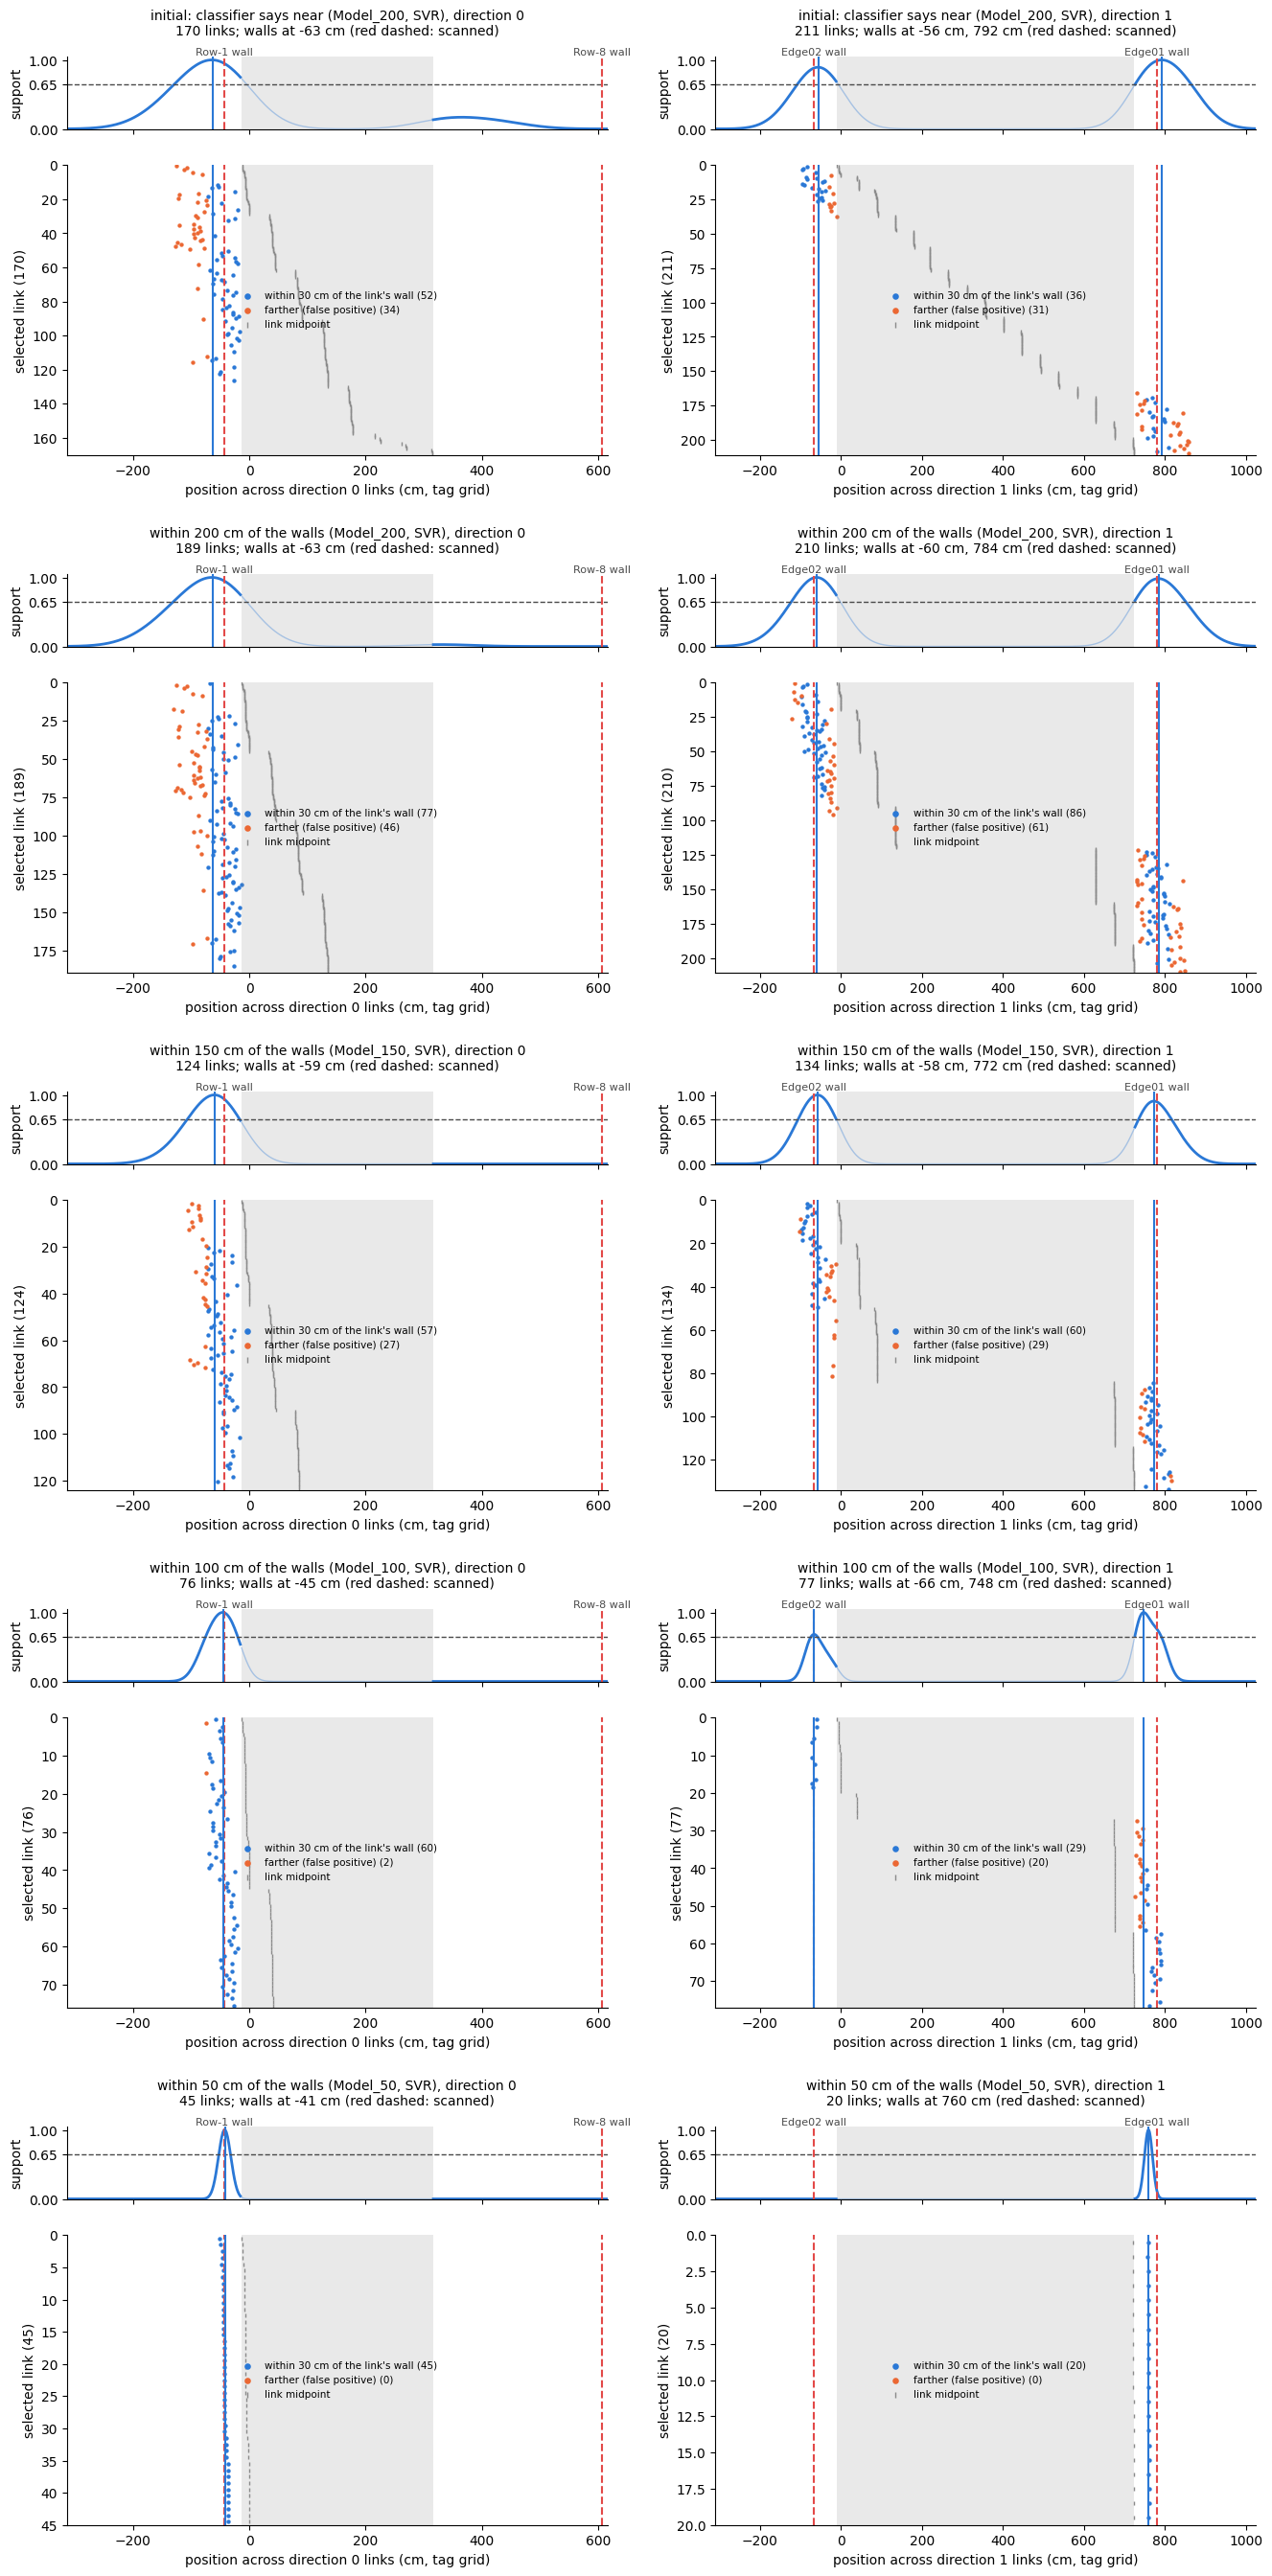

In [16]:
def plot_stages(stages, model=MODEL):
    # the cutoff figure of the earlier section, one block per stage; solid blue lines are the stage's walls
    fig = plt.figure(figsize=(16, 5.4 * len(stages)))
    for sf, st in zip(np.atleast_1d(fig.subfigures(len(stages), 1)), stages):
        axes = sf.subplots(2, 2, height_ratios=[1, 4], sharex="col")
        for k, d in enumerate((0, 1)):
            top, ax = axes[0, k], axes[1, k]
            if d not in st["info"]:
                top.set_visible(False); ax.set_visible(False)
                continue
            e, s, (lo, hi) = st["info"][d], S_IT[d], TAGS[d]
            idx = e["idx"]
            correct = np.abs(e["cand"] - link_true_wall[idx][:, None]) <= ITER_TOL_CM
            top.plot(s, np.where(e["beyond"], e["prof"], np.nan), color="#2a78d6", lw=2)
            top.plot(s, np.where(e["beyond"], np.nan, e["prof"]), color="#2a78d6", lw=1, alpha=0.35)
            top.axhline(ITER_CUTOFF, color="#4a4a4a", ls="--", lw=1)
            rows = np.broadcast_to(np.arange(len(idx))[:, None] + 0.5, e["cand"].shape)
            for ok, color, lab in [(True, "#2a78d6", f"within {ITER_TOL_CM} cm of the link's wall"),
                                   (False, "#eb6834", "farther (false positive)")]:
                mm = e["keep"] & (correct == ok)
                ax.scatter(e["cand"][mm], rows[mm], s=10, color=color, lw=0, label=f"{lab} ({mm.sum()})")
            ax.scatter(c_all[idx], np.arange(len(idx)) + 0.5, marker="|", s=10, color="#8a8a8a", lw=1,
                       label="link midpoint")
            for a in (top, ax):
                a.axvspan(lo, hi, color="#8a8a8a", alpha=0.18, lw=0)
                for t in TRUE_GRID[d].values():
                    a.axvline(t, color="#e34948", ls="--", lw=1.5)
                for w in st["walls"][d].values():
                    a.axvline(w, color="#2a78d6", lw=1.5)
                for side in ("top", "right"):
                    a.spines[side].set_visible(False)
            xlim = (lo - 300, hi + 300)
            for n, t in TRUE_GRID[d].items():
                if xlim[0] < t < xlim[1]:
                    top.text(t, 1.0, n, transform=top.get_xaxis_transform(), ha="center", va="bottom", fontsize=8,
                             color="#4a4a4a")
            top.set_ylim(0, 1.05); top.set_ylabel("support"); top.set_yticks([0, ITER_CUTOFF, 1])
            est_txt = ", ".join(f"{w:.0f} cm" for w in st["walls"][d].values()) or "none"
            mname = "Model_∞" if st["cap"] is None else f"Model_{st['cap']}"
            top.set_title(f"{st['label']} ({mname}, {model}), direction {d}\n"
                          f"{len(idx)} links; walls at {est_txt} (red dashed: scanned)", fontsize=10, pad=16)
            ax.set_xlim(*xlim); ax.set_ylim(len(idx), 0)
            ax.set_xlabel(f"position across direction {d} links (cm, tag grid)")
            ax.set_ylabel(f"selected link ({len(idx)})")
            ax.legend(frameon=False, fontsize=7.5, loc="center",
                      bbox_to_anchor=(((lo + hi) / 2 - xlim[0]) / (xlim[1] - xlim[0]), 0.5), markerscale=1.5)
    plt.show()

plot_stages(stages)


### Wall error after each step

This is the distance between each estimated wall and the scanned one, for every wall that some link is closest to. An x
means no wall passed the cutoff on that side at that step. The green band is the
10–15 cm goal. The figure is also saved as `reconstruction_out/iteration_wall_error.png`.

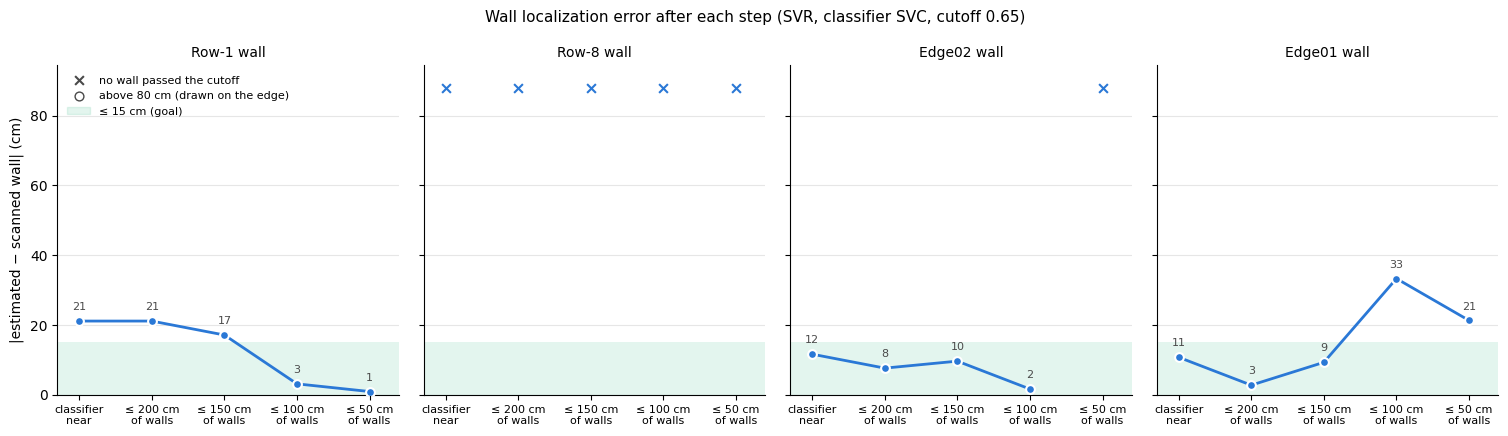

In [17]:
def wall_errors(stages):
    # |estimated − scanned| (cm) per stage for each wall that some link is closest to (NaN: no wall passed the cutoff
    # there). The Row-8 wall only has links from the experiments in rows 4–8 (16, 17).
    linked = {w.split(" (")[0] for w in meta_all["wall"]}
    out = {}
    for d, side in ((0, "low"), (0, "high"), (1, "low"), (1, "high")):
        lo, hi = TAGS[d]
        tw = {n: t for n, t in TRUE_GRID[d].items() if (t < lo if side == "low" else t > hi)}
        if not tw:
            continue
        name = min(tw, key=lambda n: abs(tw[n] - (lo if side == "low" else hi)))
        if name not in linked:
            continue
        out[name] = np.array([abs(st["walls"][d][side] - tw[name]) if side in st["walls"][d] else np.nan
                              for st in stages])
    return out

YCAP = 80                                            # errors above this are drawn on the edge, hollow, with their value
xlab = ["classifier\nnear"] + ["fallback\nall links, Model_∞" if st["cap"] is None else f"≤ {st['cap']} cm\nof walls"
                                 for st in stages[1:]]
errs, col = wall_errors(stages), "#2a78d6"
fig, axes = plt.subplots(1, len(errs), figsize=(3.8 * len(errs), 4.4), sharey=True, squeeze=False)
axes = axes[0]
for ax, (wname, e) in zip(axes, errs.items()):
    ax.axhspan(0, 15, color="#1baf7a", alpha=0.12, lw=0)
    x = np.arange(len(e))
    ok, big, none = np.isfinite(e) & (e <= YCAP), np.isfinite(e) & (e > YCAP), ~np.isfinite(e)
    ax.plot(x, np.where(np.isfinite(e), np.minimum(e, YCAP), np.nan), color=col, lw=2)
    ax.scatter(x[ok], e[ok], s=40, color=col, edgecolor="white", lw=1.5, zorder=3)
    ax.scatter(x[big], np.full(big.sum(), YCAP), s=40, facecolor="white", edgecolor=col, lw=1.5, zorder=3)
    ax.scatter(x[none], np.full(none.sum(), YCAP * 1.1), s=40, marker="x", color=col, lw=1.5, zorder=3)
    for xi in x[np.isfinite(e)]:
        ax.annotate(f"{e[xi]:.0f}", (xi, min(e[xi], YCAP)), xytext=(0, 8), textcoords="offset points", ha="center",
                    fontsize=8, color="#4a4a4a")
    ax.set_xticks(range(len(xlab)), xlab, fontsize=8)
    ax.set_xlim(-0.3, len(xlab) - 0.6)
    ax.set_ylim(0, YCAP * 1.18)
    ax.set_title(wname, fontsize=10)
    ax.grid(axis="y", color="#e6e6e6", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("|estimated − scanned wall| (cm)")
axes[0].scatter([], [], s=40, marker="x", color="#4a4a4a", label="no wall passed the cutoff")
axes[0].scatter([], [], s=40, facecolor="white", edgecolor="#4a4a4a", label=f"above {YCAP} cm (drawn on the edge)")
axes[0].fill_between([], [], color="#1baf7a", alpha=0.12, label="≤ 15 cm (goal)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle(f"Wall localization error after each step ({MODEL}, classifier {CLASSIFIER}, cutoff {ITER_CUTOFF:g})",
             fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "iteration_wall_error.png", dpi=150)
plt.show()


### Final estimated walls on the room

The scanned room (grey, points at 1–2 m height) with the final estimated walls (blue) and the walls fitted to the
scan (red dashed). A side's final wall is its last estimate that is not null: if a wall drops out at a later step,
the estimate from the last step that still had it is drawn. Each estimate is labelled with its distance to the
nearest scanned wall, or "false wall" when none is within 100 cm, and the step it comes from. The figure is also
saved as `reconstruction_out/iteration_room_map.png`.

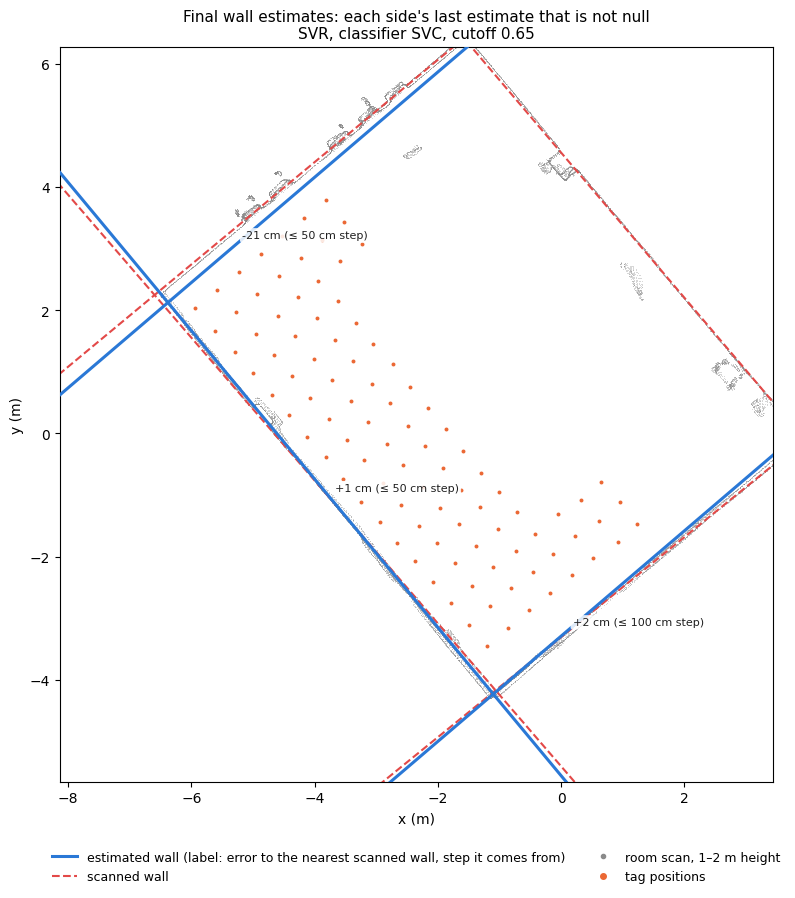

In [18]:
def wall_line(d, s, half=12):
    # an estimated wall of direction d at position s (cm along U[d]): a line parallel to the links, in metres
    v = np.array([-U[d][1], U[d][0]])
    P = O + s / 100 * U[d]
    return P + np.outer([-half, half], v), P + ((M_ALL - P) @ v) * v       # segment, point nearest the tags

def nearest_true(d, s):
    name = min(TRUE_GRID[d], key=lambda n: abs(TRUE_GRID[d][n] - s))
    return name, s - TRUE_GRID[d][name]

def step_name(st):
    return "fallback" if st["cap"] is None else f"≤ {st['cap']} cm" if st is not stages[0] else "classifier"

def final_walls(stages):
    # each side's last estimate that is not null, with the step it comes from
    final = {0: {}, 1: {}}
    for st in stages:
        for d in (0, 1):
            for side, w in st["walls"][d].items():
                final[d][side] = (w, step_name(st))
    return final

def draw_estimates(ax, final):
    ax.scatter(*room.T, s=0.3, color="#8a8a8a", alpha=0.4, lw=0, rasterized=True)
    for wname, (p, n, d) in walls.items():
        u = np.array([-n[1], n[0]])
        ax.plot(*(p + np.outer([-12, 12], u)).T, color="#e34948", lw=1.5, ls="--")
    ax.scatter(*tag_xy.T, s=8, color="#eb6834", lw=0, zorder=3)
    for d in (0, 1):
        for side, (s, step) in final[d].items():
            seg, at = wall_line(d, s)
            ax.plot(*seg.T, color="#2a78d6", lw=2.2, zorder=4)
            name, err = nearest_true(d, s)
            txt = (f"{err:+.0f} cm" if abs(err) <= 100 else "false wall") + f" ({step} step)"
            ax.annotate(txt, at, xytext=(4, 4), textcoords="offset points", fontsize=8, color="#1f1f1f", zorder=5,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
    ax.set_xlim(lo_xy[0], hi_xy[0]); ax.set_ylim(lo_xy[1], hi_xy[1]); ax.set_aspect("equal")
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")

fig, ax = plt.subplots(figsize=(10, 9))
draw_estimates(ax, final_walls(stages))
handles = [plt.Line2D([], [], color="#2a78d6", lw=2.2, label="estimated wall (label: error to the nearest scanned wall, step it comes from)"),
           plt.Line2D([], [], color="#e34948", lw=1.5, ls="--", label="scanned wall"),
           plt.Line2D([], [], color="#8a8a8a", marker="o", ls="none", ms=3, label="room scan, 1–2 m height"),
           plt.Line2D([], [], color="#eb6834", marker="o", ls="none", ms=4, label="tag positions")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 0))
ax.set_title("Final wall estimates: each side's last estimate that is not null\n"
             f"{MODEL}, classifier {CLASSIFIER}, cutoff {ITER_CUTOFF:g}", fontsize=11)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(OUT / "iteration_room_map.png", dpi=130)
plt.show()


### Reading the iteration (run saved here: experiments 1–15, 46 cm links, SVR, SVC, cutoff 0.65, no fallback)

Estimated minus scanned wall, per step. Every link is predicted by its step's Model_X.

| step | Row-1 | Edge02 | Edge01 | false wall (Row-8 side) |
|---|---|---|---|---|
| 0. classifier near | −17 | +15 | +20 | 259 cm |
| 1. ≤ 200 cm of walls | −19 | +5 | +2 | 269 cm |
| 2. ≤ 150 cm | −17 | +25 | −18 | 245 cm |
| 3. ≤ 100 cm | −7 | lost | −22 | 235 cm |
| 4. ≤ 50 cm | +1 | lost | −22 | |

- **Edge02 is found at the first step without the fallback.** Its support there is 0.68, which passes 0.65. It
  gets to 5 cm at ≤ 200 cm.
- **Edge02 drops out at ≤ 100 cm.** Its support there is 0.63, just below the cutoff, against 1.0 for Edge01.
- **The false wall passes every step that has links near it.** It is at about 235–269 cm, and it drops out only at
  ≤ 50 cm, where no link is within 50 cm of it.
- **Row-1 and Edge01 are unchanged.** Row-1 goes 17–19 → 7 → 1 cm, which below 100 cm is row snapping, not RF.
  Edge01 is best at ≤ 200 cm (2 cm) and about 20 cm off after that.